# 09 Thực nghiệm kiểm thử CCHEF Heuristic Agent (`H1` → `H7`, Grid Search, Round-Robin & Benchmark)

**Mục tiêu:** Kiểm định toàn diện hàm lượng giá **CCHEF** (`packages/agents/evaluation/`) và `HeuristicAgent` (`version 2.0.0`) theo quy trình thực nghiệm chuẩn:
1. Bộ kiểm thử chức năng bắt buộc **`HE-01` → `HE-16`** & micro-benchmark tốc độ `H1..H7`.
2. **Coarse-to-Fine Grid Search** tối ưu trọng số cho từng công thức **`H1` → `H7`** trên tập seed tách biệt hoàn toàn khỏi tập test:
   - *Coarse Grid* trên `TUNING_SEEDS` (`20` ván/ứng viên: `10 vs Ruleset_A + 10 vs Random`) lần lượt `H2 → H3 (+K) → H4 (+Q) → H5 (+D) → H6 (+T/CO)`.
   - *Fine Grid & H7 Phase Tuning* trên `VALIDATION_SEEDS` (`40` ván/ứng viên vs `Ruleset_A`) → khóa toàn bộ cấu hình tối ưu `TUNED_VARIANT_CFGS["H1".."H7"]` trước khi đụng tới `TEST_SEEDS`.
3. **Giải đấu vòng tròn (Round-Robin) `H1 → H7`:** Đủ $\binom{7}{2} = 21$ cặp, mỗi cặp **`200` ván** (**100 Đỏ đi trước + 100 Xanh đi sau**) trên `TEST_SEEDS` ở chế độ `default` (`4,200` ván) nhằm đo chính xác sự đóng góp biên của từng công thức từ `H1` tới `H7`.
4. **Đánh giá toàn bộ `H1 → H7` trước hai Baseline đối chứng (`RandomAgent` & `RuleBasedAgent` [`Ruleset_A`]):**
   - Mỗi cặp **`200` ván** (**100 Đỏ đi trước + 100 Xanh đi sau**) trên `TEST_SEEDS`.
   - Chạy đầy đủ ở cả hai chế độ ngân sách: **`default`** (`2,800` ván) và **`controlled (1000 ms)`** (`2,800` ván).
5. **Lưu trữ phân cấp theo cặp đấu & Checkpoint/Resume:** Toàn bộ `game_records/` được chia thư mục theo từng chế độ & cặp agent đấu với nhau (`game_records/<mode>/<category>/<agent_a>_vs_<agent_b>/game_XXXX.json`), kèm checkpoint từng cặp (`checkpoints/`) để tiết kiệm RAM và khôi phục an toàn nếu bị gián đoạn; theo dõi song song qua **Weights & Biases (`wandb`)**.

> **Quy ước lượng giá, baseline đối chứng & phần cứng:**
> - Hàm lượng giá tính từ **góc nhìn phe thực hiện nước đi tại trạng thái kết thúc lượt (`post_action_perspective` cho nước đơn và `compound_turn_eot_perspective` sau `END_TURN` cho lượt ghép 1 ply)**.
> - Theo `DEC-022`, `PIECE_POINTS[HEADQUARTERS] = 10` và `CCHEF_BASE_POINTS[COMMANDER] = 0.0` (điều kiện thắng/thua xử lý ngoài tổng tuyến tính bằng `±1_000_000`).
> - **Baseline `rules` đối chứng:** Sử dụng **`Ruleset_A` (`enable_check_rule = False`)** — cấu hình tối ưu hơn được chốt từ thực nghiệm `08_test_rules_agent.ipynb` (`rul_20261111T083501Z`: `Ruleset_A` thắng `Ruleset_B` `63W-2D-34L`, Score `0.6465`).
> - **Thực thi CPU đa tiến trình:** Game engine Cờ Tư Lệnh và `CCHEFEvaluator` xử lý tuần tự/cây quy tắc thuần Python (không dùng phép toán tensor CUDA), nên notebook chạy song song bằng `ProcessPoolExecutor` trên CPU.

## I. Import thư viện

In [1]:
import gc
from itertools import product
from pathlib import Path
import shutil
import sys

_cwd = Path.cwd().resolve()
_exp_dir = next(
    (p / "research" / "experiments" for p in (_cwd, *_cwd.parents) if (p / "research" / "experiments" / "common").is_dir()),
    _cwd if (_cwd / "common").is_dir() else None,
)
if _exp_dir is None:
    raise FileNotFoundError("Không tìm thấy thư mục `research/experiments/common`.")
if str(_exp_dir) not in sys.path:
    sys.path.insert(0, str(_exp_dir))

from common.imports import *
from common import (
    ExperimentLogger,
    ProfileScope,
    bootstrap_confidence_interval,
    capture_memory_snapshot,
    compute_state_hash,
    create_agent,
    finish_wandb_run,
    format_action_str,
    get_environment_info,
    get_git_revision,
    init_wandb_run,
    load_experiment_config,
    log_wandb_metrics,
    log_wandb_table,
    plot_decision_time_comparison,
    plot_matchup_heatmap,
    plot_metric_bar,
    plot_sensitivity_curve,
    plot_wdl_stacked_bar,
    run_head_to_head,
    run_match,
    sanitize_path_segment,
    set_global_seed,
    summarize_pair_results,
    summarize_red_blue_splits,
    wilson_confidence_interval,
)

from commander_game_engine.engine import preview_action
from commander_game_engine.game_state import Piece, PieceType, Player
from agents import CCHEFEvaluator, FEATURE_NAMES, HeuristicAgent, NoLegalActionsError
from agents.evaluation import (
    CCHEF_BASE_POINTS,
    DEFAULT_CCHEF_WEIGHTS,
    DEFAULT_FEATURE_SCALES,
    DEFAULT_PHASE_MODIFIERS,
    EvalContext,
    TERMINAL_WIN_SCORE,
    VARIANT_ENABLED_FEATURES,
    VARIANT_NAMES,
    compute_action_tc,
    compute_observable_phase,
    normalize_weights,
    side_king_risk,
    side_tr_risk,
)

env_info = get_environment_info()
git_info = get_git_revision()
try:
    from IPython.display import display
except ImportError:
    display = print

load_dotenv(PROJECT_ROOT / ".env")
try:
    wandb_api_key_ready = bool(os.environ.get("WANDB_API_KEY"))
    if not wandb_api_key_ready and HAS_WANDB and wandb is not None:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            wandb_api_key_ready = bool(getattr(getattr(wandb, "api", None), "api_key", None))
except Exception:
    wandb_api_key_ready = False
gpu_available = bool(torch is not None and torch.cuda.is_available())

print(f"Python {env_info['python_version']} | CPU logical cores: {env_info['cpu_count']} | CUDA: {gpu_available} | Git: {git_info.get('commit')}")
print(f"W&B: {getattr(wandb, '__version__', 'N/A')} | API key ready: {wandb_api_key_ready}")
print(f"CCHEF Features: {FEATURE_NAMES} | Variants: {VARIANT_NAMES} | HQ={CCHEF_BASE_POINTS[PieceType.HEADQUARTERS]}, CMD={CCHEF_BASE_POINTS[PieceType.COMMANDER]}")

d:\Commander-Chess-AI\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
wandb: WARNING wandb.api and wandb.ensure_configured() are deprecated and will be removed in a future release. To check for credentials without prompting, use wandb.login(prompt=False).


Python 3.10.0 | CPU logical cores: 16 | CUDA: False | Git: 6d13556e99682a7f8d189b765e75198220a6cc7c
W&B: 0.31.0 | API key ready: True
CCHEF Features: ('M', 'K', 'Q', 'P', 'C', 'D', 'T') | Variants: ('H1', 'H2', 'H3', 'H4', 'H5', 'H6', 'H7') | HQ=10.0, CMD=0.0


## II. Cấu hình thực nghiệm, Resume Checkpoint & phân tách dữ liệu (`Tuning` / `Validation` / `Test`)

In [2]:
cfg = load_experiment_config("09_test_heuristic_agent")

# --- W&B & tài nguyên thực thi ---
USE_WANDB = True
WANDB_PROJECT = cfg.get("wandb_project", "commander-chess-ai")
WANDB_MODE = "online"            # "online" | "offline" | "disabled"
LOG_WANDB_ARTIFACTS = True
RUN_CONTROLLED_BUDGET = True

# Lưu ý RAM: mỗi worker Python chiếm ~100-140 MB RSS. Nên đóng ứng dụng nặng nền trước khi chạy toàn phần.
MAX_WORKERS = max(1, min(8, (os.cpu_count() or 2) // 2))
# Chế độ `controlled (1000 ms)` giới hạn worker <= 4 để tránh tranh chấp CPU làm sai lệch đồng hồ thực tế
CONTROLLED_MAX_WORKERS = max(1, min(4, (os.cpu_count() or 2) // 3))

# --- Khôi phục checkpoint khi chạy dài ngày ---
# Nếu lần chạy bị ngắt giữa chừng, dán tên thư mục RUN_ID trước đó (VD: "cchef_20261112T133000Z") vào đây để chạy tiếp.
RESUME_RUN_ID: str | None = "cchef_20261112T080947Z"
RUN_EXTRA_ABLATION_AND_SELFPLAY = False  # Tùy chọn thêm (40 ván CO_On/Off & Self-Play); mặc định False để tập trung pipeline chính

# --- Ngân sách ván đấu & phân tách seed tuyệt đối ---
# 3 tập seed hoàn toàn rời nhau để tránh rò rỉ dữ liệu test vào Grid Search:
TUNING_SEEDS = [11, 22, 33, 44, 55]                       # Chỉ dùng cho Coarse Grid Search
VALIDATION_SEEDS = [101, 202, 303, 404, 505]              # Chỉ dùng cho Fine Grid & H7 Phase Tuning
TEST_SEEDS = list(cfg["seeds"])                           # [2026, 42, 0, 7, 123, 1337, 2024, 2025, 3407, 9999] -> CHỈ DÙNG Ở 5.3 & 5.4!
assert not (set(TUNING_SEEDS) & set(VALIDATION_SEEDS))
assert not (set(TUNING_SEEDS) & set(TEST_SEEDS))
assert not (set(VALIDATION_SEEDS) & set(TEST_SEEDS))

ROUND_ROBIN_GAMES = int(cfg["games_per_pair"])            # 200 ván/cặp cho Round-Robin H1..H7 (21 cặp = 4,200 ván)
BENCHMARK_GAMES = int(cfg["games_per_pair"])              # 200 ván/cặp cho H1..H7 vs Random & Ruleset_A (default + controlled = 5,600 ván)
GRID_COARSE_GAMES = 20                                    # 20 ván/ứng viên Coarse (10 vs Ruleset_A + 10 vs Random) trên TUNING_SEEDS
GRID_FINE_GAMES = 40                                      # 40 ván/ứng viên Fine & H7 Phase trên VALIDATION_SEEDS
EXTRA_ABLATION_GAMES = 40                                 # Chỉ dùng nếu bật RUN_EXTRA_ABLATION_AND_SELFPLAY

MAX_TURNS = int(cfg["max_turns"])
DRAW_ON_MAX_TURNS = bool(cfg.get("draw_on_max_turns", False))

if RESUME_RUN_ID:
    RUN_ID = str(RESUME_RUN_ID).strip()
    IS_RESUMING = True
    _resume_dir = Path(cfg["resolved_output_dir"]) / RUN_ID
    if not _resume_dir.is_dir():
        raise FileNotFoundError(f"Không tìm thấy thư mục RUN_ID để resume: {_resume_dir}")
    run_logger = ExperimentLogger(_resume_dir, allow_overwrite=True)
else:
    RUN_ID = f"cchef_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}"
    IS_RESUMING = False
    run_logger = ExperimentLogger.from_config(cfg, run_tag=RUN_ID)

BASE_HEURISTIC_CFG = deepcopy(cfg["agent_configs"]["heuristic"])
RULES_BASELINE_CFG = deepcopy(cfg["agent_configs"]["rules"])
assert RULES_BASELINE_CFG.get("ruleset_name") == "Ruleset_A" and RULES_BASELINE_CFG.get("enable_check_rule") is False, (
    f"Baseline RuleBased cho thực nghiệm 09 phải là Ruleset_A (`enable_check_rule=False`), nhận được: {RULES_BASELINE_CFG}"
)
RULES_LABEL = str(RULES_BASELINE_CFG.get("ruleset_name", "Ruleset_A"))

# Các cấu hình điều chỉnh pha cho H7 (khảo sát trong 5.2.5 trên nền bộ trọng số H6 tốt nhất)
H7_PHASE_PRESETS: dict[str, dict[str, dict[str, float]]] = {
    "H7_default_cchef": deepcopy(DEFAULT_PHASE_MODIFIERS),
    "H7_deploy_endking": {
        "opening": {"M": 0.80, "K": 0.90, "Q": 0.85, "P": 1.35, "C": 1.35, "D": 1.85, "T": 0.90},
        "middlegame": {"M": 1.00, "K": 1.00, "Q": 1.00, "P": 1.00, "C": 1.00, "D": 1.00, "T": 1.00},
        "endgame": {"M": 1.30, "K": 1.50, "Q": 1.60, "P": 0.70, "C": 0.90, "D": 0.35, "T": 1.15},
    },
    "H7_tactical_mid_end": {
        "opening": {"M": 0.90, "K": 0.95, "Q": 0.95, "P": 1.30, "C": 1.25, "D": 1.50, "T": 1.00},
        "middlegame": {"M": 0.95, "K": 1.05, "Q": 1.10, "P": 0.95, "C": 1.00, "D": 0.95, "T": 1.25},
        "endgame": {"M": 1.25, "K": 1.35, "Q": 1.45, "P": 0.80, "C": 0.95, "D": 0.45, "T": 1.20},
    },
    "H7_mild_shift": {
        "opening": {"M": 0.92, "K": 0.95, "Q": 0.95, "P": 1.20, "C": 1.15, "D": 1.35, "T": 0.95},
        "middlegame": {"M": 1.00, "K": 1.00, "Q": 1.00, "P": 1.00, "C": 1.00, "D": 1.00, "T": 1.00},
        "endgame": {"M": 1.15, "K": 1.25, "Q": 1.25, "P": 0.85, "C": 0.95, "D": 0.65, "T": 1.10},
    },
}

set_global_seed(cfg["seed"])

mem_now = capture_memory_snapshot()
avail_ram_mb = mem_now.get("system_available_mb")
if avail_ram_mb is not None and avail_ram_mb < 1500:
    warnings.warn(
        f"RAM hệ thống trống chỉ còn {avail_ram_mb:.0f} MB. Khuyến nghị đóng bớt ứng dụng/tab trình duyệt trước khi chạy {MAX_WORKERS} worker song song!",
        ResourceWarning,
    )

print(f"Run ID           : {RUN_ID} (resume={IS_RESUMING})")
print(f"Output Dir       : {run_logger.run_dir}")
print(f"Workers          : default={MAX_WORKERS}, controlled={CONTROLLED_MAX_WORKERS} | System Free RAM: {avail_ram_mb} MB")
print(f"W&B Config       : use={USE_WANDB}, mode={WANDB_MODE}, project={WANDB_PROJECT}")
print(f"TUNING_SEEDS     : {TUNING_SEEDS} ({GRID_COARSE_GAMES} games/cand)")
print(f"VALIDATION_SEEDS : {VALIDATION_SEEDS} ({GRID_FINE_GAMES} games/cand)")
print(f"TEST_SEEDS       : {TEST_SEEDS} (Round-Robin={ROUND_ROBIN_GAMES}/cặp, Benchmark={BENCHMARK_GAMES}/cặp)")
print(f"Ruleset Baseline : {RULES_LABEL} (id={RULES_BASELINE_CFG['agent_config_id']}, enable_check_rule={RULES_BASELINE_CFG['enable_check_rule']})")

Run ID           : cchef_20261112T080947Z (resume=True)
Output Dir       : D:\Commander-Chess-AI\research\results\09_test_heuristic_agent\cchef_20261112T080947Z
Workers          : default=8, controlled=4 | System Free RAM: None MB
W&B Config       : use=True, mode=online, project=commander-chess-ai
TUNING_SEEDS     : [11, 22, 33, 44, 55] (20 games/cand)
VALIDATION_SEEDS : [101, 202, 303, 404, 505] (40 games/cand)
TEST_SEEDS       : [2026, 42, 0, 7, 123, 1337, 2024, 2025, 3407, 9999] (Round-Robin=200/cặp, Benchmark=200/cặp)
Ruleset Baseline : Ruleset_A (id=Ruleset_A, enable_check_rule=False)


## III. Khởi tạo môi trường, `CCHEFEvaluator` và Smoke Test

In [3]:
def _safe_wandb_start(
    *,
    run_name: str,
    group: str,
    job_type: str,
    tags: list[str],
    extra_config: dict[str, Any],
) -> Any | None:
    if not USE_WANDB or WANDB_MODE == "disabled":
        return None
    if getattr(wandb, "run", None) is not None:
        finish_wandb_run(wandb.run)
    # Loại bỏ mọi khóa nhạy cảm trước khi đẩy lên W&B
    clean_cfg = {
        "experiment_id": cfg["experiment_id"],
        "run_id": RUN_ID,
        "rules_version": cfg["rules_version"],
        "engine_version": cfg["engine_version"],
        "git_commit": git_info.get("commit"),
        "seed": cfg["seed"],
        **extra_config,
    }
    return init_wandb_run(
        clean_cfg,
        project=WANDB_PROJECT,
        name=run_name,
        group=group,
        job_type=job_type,
        tags=tags,
        mode=WANDB_MODE,
        enabled=USE_WANDB,
        wandb_dir=cfg["resolved_wandb_dir"],
    )


init_state = create_initial_state()
init_legal = generate_legal_actions(init_state)

heuristic_h6 = create_agent(
    "heuristic",
    config={**BASE_HEURISTIC_CFG, "variant": "H6", "weight_config_id": "H6_cchef_init"},
    seed=cfg["seed"],
    instance_name="H6_init",
)
heuristic_h7 = create_agent(
    "heuristic",
    config={**BASE_HEURISTIC_CFG, "variant": "H7", "weight_config_id": "H7_cchef_init"},
    seed=cfg["seed"],
    instance_name="H7_init",
)

smoke_h6 = heuristic_h6.select_action(init_state, init_legal)
smoke_h7 = heuristic_h7.select_action(init_state, init_legal)
rules_baseline = create_agent("rules", config=RULES_BASELINE_CFG, seed=cfg["seed"], instance_name="rules")
assert rules_baseline.ruleset_name == "Ruleset_A" and rules_baseline.enable_check_rule is False

print(f"H6 variant       : {smoke_h6.metadata['heuristic_variant']} | basis={smoke_h6.metadata['evaluation_basis']} | co_enabled={smoke_h6.metadata['co_enabled']}")
print(f"H6 chosen        : {format_action_str(smoke_h6.action)} | score={smoke_h6.metadata['heuristic_score']:.5f}")
print(f"H6 eval states   : {smoke_h6.metadata['evaluated_states_count']} | compound_branches={smoke_h6.metadata['compound_actions_count']}")
print(f"H6 effective w   : {smoke_h6.metadata['effective_weights']}")
print(f"H7 phase@init    : {smoke_h7.metadata['game_phase']}")
print(f"H7 effective w   : { {k: round(v, 4) for k, v in smoke_h7.metadata['effective_weights'].items()} }")
print(f"Rules baseline   : {rules_baseline.ruleset_name} (enable_check_rule={rules_baseline.enable_check_rule}) | config_id={rules_baseline.config.get('agent_config_id')}")
print(f"Memory snapshot  : {capture_memory_snapshot()}")


H6 variant       : H6 | basis=post_action_perspective | co_enabled=True
H6 chosen        : MOVE:red_navy_1@(1,1)->(5,1) | score=0.02925
H6 eval states   : 114 | compound_branches=0
H6 effective w   : {'M': 0.25, 'K': 0.25, 'Q': 0.15, 'P': 0.1, 'C': 0.05, 'D': 0.05, 'T': 0.15}
H7 phase@init    : {'phase_label': 'opening', 'opening': 0.542763157894737, 'middlegame': 0.45723684210526305, 'endgame': 0.0, 'material_ratio': 1.0, 'deployment_ratio': 0.34375}
H7 effective w   : {'M': 0.2303, 'K': 0.2371, 'Q': 0.1422, 'P': 0.1193, 'C': 0.0569, 'D': 0.0678, 'T': 0.1463}
Rules baseline   : Ruleset_A (enable_check_rule=False) | config_id=Ruleset_A
Memory snapshot  : {'process_rss_mb': 224.2109375, 'cpu_count': 16, 'process_cpu_percent': 0.0, 'vram_available': False, 'vram_allocated_mb': None, 'vram_reserved_mb': None}


## IV. Kiểm thử chức năng bắt buộc (`HE-01` → `HE-16`) & Benchmark tốc độ `H1..H7`

In [4]:
def _mk_state(pieces: list[Piece], current_player: Player = Player.RED, turn_number: int = 1) -> GameState:
    st = GameState(board=Board(), pieces={p.id: p for p in pieces}, current_player=current_player, turn_number=turn_number)
    st.validate_structure()
    return st


def _mirror_y_state(state: GameState) -> GameState:
    rows = state.board.ROWS
    mirrored_pieces = {
        pid: Piece(
            id=p.id,
            piece_type=p.piece_type,
            owner=(Player.BLUE if p.owner == Player.RED else Player.RED),
            position=((rows - 1 - p.position[0], p.position[1]) if p.position is not None else None),
            carried_by=p.carried_by,
            cargo=list(p.cargo),
            is_heroic=p.is_heroic,
        )
        for pid, p in state.pieces.items()
    }
    st = GameState(
        board=Board(),
        pieces=mirrored_pieces,
        current_player=(Player.BLUE if state.current_player == Player.RED else Player.RED),
        turn_number=state.turn_number,
    )
    st.validate_structure()
    return st


he_results: list[dict[str, Any]] = []


def _record_he(test_id: str, passed: bool, detail: str) -> None:
    he_results.append({"id": test_id, "passed": bool(passed), "detail": detail})
    assert passed, f"[{test_id}] Thất bại: {detail}"


ev_h6 = CCHEFEvaluator({"variant": "H6"})

# HE-01: Ăn Xe tăng đơn lẻ -> Material +20đ (HQ=10, Tư lệnh=0)
assert CCHEF_BASE_POINTS[PieceType.HEADQUARTERS] == 10.0 and CCHEF_BASE_POINTS[PieceType.COMMANDER] == 0.0
s_he01 = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_mil_b", PieceType.MILITIA, Player.RED, (1, 8)),
    Piece("red_inf_b", PieceType.INFANTRY, Player.RED, (1, 9)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (4, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 7)),
    Piece("blue_mil_b", PieceType.MILITIA, Player.BLUE, (10, 8)),
    Piece("blue_inf_b", PieceType.INFANTRY, Player.BLUE, (10, 9)),
    Piece("blue_tank_1", PieceType.TANK, Player.BLUE, (5, 5)),
])
res_he01 = preview_action(s_he01, AtomicAction(ActionType.CAPTURE, "red_tank_1", (4, 5), (5, 5), target_piece_id="blue_tank_1"))
tc_he01 = compute_action_tc(s_he01, res_he01, Player.RED)
_record_he("HE-01", res_he01.accepted and tc_he01["tc"] == 20.0 and ev_h6.compute_raw_components(res_he01.state, Player.RED)["M"] == 20.0, f"HQ=10, CMD=0, gain={tc_he01['gain']}")

# HE-02: Xe tăng 20 chở Dân quân 10 bị diệt -> 30đ
s_he02 = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_art_1", PieceType.ARTILLERY, Player.RED, (4, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 7)),
    Piece("blue_tank_1", PieceType.TANK, Player.BLUE, (5, 5), cargo=["blue_mil_1"]),
    Piece("blue_mil_1", PieceType.MILITIA, Player.BLUE, None, carried_by="blue_tank_1"),
])
sv2 = EvalContext.from_state(s_he02).stack_value("blue_tank_1")
res_he02 = preview_action(s_he02, AtomicAction(ActionType.CAPTURE, "red_art_1", (4, 5), (5, 5), target_piece_id="blue_tank_1"))
_record_he("HE-02", sv2 == 30.0 and compute_action_tc(s_he02, res_he02, Player.RED)["gain"] == 30.0, f"V_stack={sv2}")

# HE-03: Máy bay 40 -> Xe tăng 20 -> Dân quân 10 bị diệt -> 70đ (lồng 3 tầng)
s_he03 = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_art_1", PieceType.ARTILLERY, Player.RED, (3, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 7)),
    Piece("blue_air_1", PieceType.AIRCRAFT, Player.BLUE, (5, 5), cargo=["blue_tank_1"]),
    Piece("blue_tank_1", PieceType.TANK, Player.BLUE, None, carried_by="blue_air_1", cargo=["blue_mil_1"]),
    Piece("blue_mil_1", PieceType.MILITIA, Player.BLUE, None, carried_by="blue_tank_1"),
])
sv3 = EvalContext.from_state(s_he03).stack_value("blue_air_1")
res_he03 = preview_action(s_he03, AtomicAction(ActionType.CAPTURE, "red_art_1", (3, 5), (5, 5), target_piece_id="blue_air_1"))
_record_he("HE-03", sv3 == 70.0 and compute_action_tc(s_he03, res_he03, Player.RED)["gain"] == 70.0, f"Nested V_stack={sv3}")

# HE-04: Quân Anh hùng +10 Material và tăng tầm đi (C tăng)
s_he04_n = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_inf_1", PieceType.INFANTRY, Player.RED, (4, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
    Piece("blue_inf_1", PieceType.INFANTRY, Player.BLUE, (7, 5)),
])
s_he04_h = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_inf_1", PieceType.INFANTRY, Player.RED, (4, 5), is_heroic=True),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
    Piece("blue_inf_1", PieceType.INFANTRY, Player.BLUE, (7, 5)),
])
rn4, rh4 = ev_h6.compute_raw_components(s_he04_n, Player.RED), ev_h6.compute_raw_components(s_he04_h, Player.RED)
_record_he("HE-04", rh4["M"] - rn4["M"] == 10.0 and rh4["C"] > rn4["C"], f"dM={rh4['M']-rn4['M']}, C: {rn4['C']:.1f}->{rh4['C']:.1f}")

# HE-05: Chiếu nhưng quân chiếu bị ăn lại an toàn => KingRisk ≈ 0 so với chiếu thật sự nguy hiểm
s_he05_safe = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (2, 7)),
    Piece("red_art_g", PieceType.ARTILLERY, Player.RED, (0, 8)),
    Piece("blue_art_chk", PieceType.ARTILLERY, Player.BLUE, (2, 6)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 3)),
])
s_he05_danger = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 10)),
    Piece("blue_art_chk", PieceType.ARTILLERY, Player.BLUE, (3, 10)),
    Piece("blue_art_cov", PieceType.ARTILLERY, Player.BLUE, (3, 9)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 3)),
])
rk_safe = side_king_risk(EvalContext.from_state(s_he05_safe), Player.RED)
rk_danger = side_king_risk(EvalContext.from_state(s_he05_danger), Player.RED)
_record_he("HE-05", rk_safe <= 0.1 and rk_danger > rk_safe + 3.0, f"safe_risk={rk_safe:.3f}, danger_risk={rk_danger:.3f}")

# HE-06: Thắng tuyệt đối vượt mọi trọng số vị trí cực đoan
s_he06 = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 2)),
    Piece("red_tank_g", PieceType.TANK, Player.RED, (10, 9)),
    Piece("red_art_m", PieceType.ARTILLERY, Player.RED, (8, 10)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 10)),
])
ag_ext = create_agent("heuristic", config={"variant": "H6", "weights": {"M": 0.01, "K": 0.01, "Q": 0.01, "P": 100.0, "C": 0.01, "D": 0.01, "T": 0.01}}, seed=2026)
dec_he06 = ag_ext.select_action(s_he06, generate_legal_actions(s_he06))
_record_he("HE-06", dec_he06.metadata["is_terminal_candidate"] and dec_he06.metadata["heuristic_score"] >= TERMINAL_WIN_SCORE * 0.99, f"score={dec_he06.metadata['heuristic_score']:.1f}")

# HE-07, HE-08, HE-09, HE-14: CompoundTurn, CO, không đếm trùng, 1 ply
s_combo = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 3)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (7, 5), cargo=["red_inf_1"]),
    Piece("red_inf_1", PieceType.INFANTRY, Player.RED, None, carried_by="red_tank_1"),
    Piece("blue_art_1", PieceType.ARTILLERY, Player.BLUE, (8, 5)),
    Piece("blue_mil_1", PieceType.MILITIA, Player.BLUE, (7, 6)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (8, 7)),
])
ag_co_on = create_agent("heuristic", config={"variant": "H6", "enable_compound_lookahead": True, "enable_co_synergy": True, "tie_breaking": "deterministic"}, seed=42)
ag_co_off = create_agent("heuristic", config={"variant": "H6", "enable_compound_lookahead": False, "enable_co_synergy": False, "tie_breaking": "deterministic"}, seed=42)
leg_c = generate_legal_actions(s_combo)
dec_c1 = ag_co_on.select_action(s_combo, leg_c)
res_c1 = apply_action(s_combo, dec_c1.action)
same_turn_ok = (res_c1.state.compound_turn is None) or (res_c1.state.turn_number == 1)
if res_c1.state.compound_turn is not None:
    dec_c2 = ag_co_on.select_action(res_c1.state, generate_legal_actions(res_c1.state))
    res_c2 = apply_action(res_c1.state, dec_c2.action)
    removed = (set(s_combo.pieces) - set(res_c2.state.pieces)) & {"blue_art_1", "blue_mil_1"}
    m_diff = ev_h6.compute_raw_components(res_c2.state, Player.RED)["M"] - ev_h6.compute_raw_components(s_combo, Player.RED)["M"]
    hero_d = 10.0 * sum(1 for pid, p in res_c2.state.pieces.items() if p.owner == Player.RED and p.is_heroic and not s_combo.pieces[pid].is_heroic)
    expected_m = sum(CCHEF_BASE_POINTS[s_combo.pieces[pid].piece_type] for pid in removed) + hero_d
    no_dbl_ok = math.isclose(m_diff, expected_m, abs_tol=1e-9)
else:
    no_dbl_ok = True
_record_he("HE-07/08/09/14", res_c1.accepted and same_turn_ok and no_dbl_ok and dec_c1.metadata["co_enabled"] and (not ag_co_off.select_action(s_combo, leg_c).metadata["co_enabled"]), f"plan={dec_c1.metadata['compound_plan']}")

# HE-10 & HE-11 & hồi quy BOMBARD Hải quân: TR theo V_stack, AA & pháo hạm tại chỗ
s_he10 = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (5, 5), cargo=["red_mil_1"]),
    Piece("red_mil_1", PieceType.MILITIA, Player.RED, None, carried_by="red_tank_1"),
    Piece("blue_inf_att", PieceType.INFANTRY, Player.BLUE, (6, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
tr10 = side_tr_risk(EvalContext.from_state(s_he10), Player.RED)

s_he11_in = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 3)),
    Piece("red_air_1", PieceType.AIRCRAFT, Player.RED, (6, 5)),
    Piece("blue_aa_1", PieceType.ANTI_AIRCRAFT, Player.BLUE, (7, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 8)),
])
s_he11_out = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 3)),
    Piece("red_air_1", PieceType.AIRCRAFT, Player.RED, (6, 5)),
    Piece("blue_aa_1", PieceType.ANTI_AIRCRAFT, Player.BLUE, (9, 9)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 8)),
])
c11_in, c11_out = ev_h6.compute_raw_components(s_he11_in, Player.RED), ev_h6.compute_raw_components(s_he11_out, Player.RED)

s_navy_bomb = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_air_1", PieceType.AIRCRAFT, Player.RED, (5, 5)),
    Piece("red_tank_g", PieceType.TANK, Player.RED, (4, 5)),
    Piece("blue_navy_2", PieceType.NAVY, Player.BLUE, (8, 2)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
tr_navy = side_tr_risk(EvalContext.from_state(s_navy_bomb), Player.RED)
_record_he("HE-10/11", tr10 >= 24.0 and tr_navy >= 30.0 and c11_in["P"] < c11_out["P"] and c11_in["T"] < c11_out["T"], f"TR_stack={tr10:.1f}, TR_navy_bombard={tr_navy:.1f}, T_aa={c11_in['T']:.1f}<{c11_out['T']:.1f}")

# HE-12 & HE-13: Đối xứng hoàn hảo H1..H7 + không lộ mặt Tư lệnh
asym = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (4, 5), cargo=["red_inf_1"]),
    Piece("red_inf_1", PieceType.INFANTRY, Player.RED, None, carried_by="red_tank_1"),
    Piece("red_navy_1", PieceType.NAVY, Player.RED, (3, 1), cargo=["red_air_1"]),
    Piece("red_air_1", PieceType.AIRCRAFT, Player.RED, None, carried_by="red_navy_1"),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
    Piece("blue_art_1", PieceType.ARTILLERY, Player.BLUE, (8, 7)),
    Piece("blue_aa_1", PieceType.ANTI_AIRCRAFT, Player.BLUE, (9, 5)),
])
mir = _mirror_y_state(asym)
sym_ok = all(
    math.isclose(CCHEFEvaluator({"variant": v}).evaluate_state(init_state, Player.RED)[0], 0.0, abs_tol=1e-7)
    and math.isclose(
        CCHEFEvaluator({"variant": v}).evaluate_state(asym, Player.RED)[0],
        -CCHEFEvaluator({"variant": v}).evaluate_state(asym, Player.BLUE)[0],
        abs_tol=1e-9,
    )
    and math.isclose(
        CCHEFEvaluator({"variant": v}).evaluate_state(asym, Player.RED)[0],
        CCHEFEvaluator({"variant": v}).evaluate_state(mir, Player.BLUE)[0],
        abs_tol=1e-9,
    )
    for v in VARIANT_NAMES
)
s_face = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_inf_shield", PieceType.INFANTRY, Player.RED, (5, 6)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
face_ok = not any(isinstance(a, AtomicAction) and a.piece_id == "red_inf_shield" and a.end is not None and a.end[1] != 6 for a in generate_legal_actions(s_face))
_record_he("HE-12/13", sym_ok and face_ok, "E(s,RED)==-E(s,BLUE) & E(init)==0 trên H1..H7; cấm lộ mặt Tư lệnh.")

# HE-15 & HE-16: Seed reproducibility, Non-mutation, LOO renormalization & NaN/Inf sanity
ag_s1 = create_agent("heuristic", config=BASE_HEURISTIC_CFG, seed=1337)
ag_s2 = create_agent("heuristic", config=BASE_HEURISTIC_CFG, seed=1337)
h_before = compute_state_hash(init_state)
d_s1, d_s2 = ag_s1.select_action(init_state, init_legal), ag_s2.select_action(init_state, init_legal)
non_mut_ok = compute_state_hash(init_state) == h_before
repro_ok = (d_s1.action == d_s2.action) and (d_s1.metadata["heuristic_components"] == d_s2.metadata["heuristic_components"])
loo_ok = True
for f in FEATURE_NAMES:
    sub = [x for x in FEATURE_NAMES if x != f]
    ag_sub = create_agent("heuristic", config={"variant": "H6", "enabled_features": sub}, seed=7)
    d_sub = ag_sub.select_action(init_state, init_legal)
    if ag_sub.effective_weights[f] != 0.0 or not math.isclose(sum(ag_sub.effective_weights.values()), 1.0, abs_tol=1e-9) or d_sub.metadata["heuristic_components"][f] != 0.0:
        loo_ok = False
variant_scope_ok = all(
    (
        create_agent("heuristic", config={**BASE_HEURISTIC_CFG, "variant": v}, seed=7).enabled_components == VARIANT_ENABLED_FEATURES[v]
        and create_agent("heuristic", config={**BASE_HEURISTIC_CFG, "variant": v}, seed=7).enable_compound_lookahead == (v in ("H6", "H7"))
    )
    for v in VARIANT_NAMES
)
_record_he("HE-15/16", repro_ok and non_mut_ok and loo_ok and variant_scope_ok, "Tái lập seed=1337, bất biến GameState, H1..H5 tắt CO / H6..H7 bật CO, tắt từng đặc trưng M..T chuẩn hóa sum=1.")

display(pd.DataFrame(he_results))

# Micro-benchmark tốc độ evaluate_state & select_action trên bàn cờ xuất phát (114 nước hợp lệ)
bench_rows = []
for v in VARIANT_NAMES:
    ev_v = CCHEFEvaluator({"variant": v})
    t0 = time.perf_counter()
    for _ in range(40):
        ev_v.evaluate_state(init_state, Player.RED)
    eval_ms = (time.perf_counter() - t0) * 1000.0 / 40.0

    ag_v = create_agent(
        "heuristic",
        config={
            **BASE_HEURISTIC_CFG,
            "variant": v,
            "enabled_features": list(VARIANT_ENABLED_FEATURES[v]),
            "enable_compound_lookahead": (v in ("H6", "H7")),
            "enable_co_synergy": (v in ("H6", "H7")),
        },
        seed=cfg["seed"],
    )
    t1 = time.perf_counter()
    dec_v = ag_v.select_action(init_state, init_legal)
    move_ms = (time.perf_counter() - t1) * 1000.0
    bench_rows.append({
        "variant": v,
        "enabled_features": ",".join(ag_v.enabled_components),
        "eval_state_ms": round(eval_ms, 3),
        "init_select_action_ms": round(move_ms, 2),
        "evaluated_states_count": dec_v.metadata["evaluated_states_count"],
        "co_enabled": dec_v.metadata["co_enabled"],
    })
micro_bench_df = pd.DataFrame(bench_rows)
display(micro_bench_df)


,id,passed,detail
0,HE-01,True,"HQ=10, CMD=0, gain=20.0"
1,HE-02,True,V_stack=30.0
2,HE-03,True,Nested V_stack=70.0
3,HE-04,True,"dM=10.0, C: 0.0->10.3"
4,HE-05,True,"safe_risk=0.000, danger_risk=4.000"
5,HE-06,True,score=999999.0
6,HE-07/08/09/14,True,"plan=['CAPTURE:red_inf_1@(7,5)->(7,6)#target=b..."
7,HE-10/11,True,"TR_stack=29.1, TR_navy_bombard=37.6, T_aa=-6.4..."
8,HE-12/13,True,"E(s,RED)==-E(s,BLUE) & E(init)==0 trên H1..H7;..."
9,HE-15/16,True,"Tái lập seed=1337, bất biến GameState, H1..H5 ..."


,variant,enabled_features,eval_state_ms,init_select_action_ms,evaluated_states_count,co_enabled
0,H1,M,0.095,79.14,114,False
1,H2,"M,P,C",0.838,164.17,114,False
2,H3,"M,P,C,K",0.813,156.61,114,False
3,H4,"M,P,C,K,Q",0.832,187.51,114,False
4,H5,"M,P,C,K,Q,D",1.102,184.44,114,False
5,H6,"M,K,Q,P,C,D,T",1.561,231.23,114,True
6,H7,"M,K,Q,P,C,D,T",1.407,246.48,114,True


## V. Thực nghiệm Grid Search (`H1..H7`), Round-Robin (`21×200`) & Benchmark (`default` + `controlled 1000 ms`)

Quy trình tuân thủ nghiêm ngặt **chống rò rỉ dữ liệu test** (baseline Rule-based = **`Ruleset_A`**, `enable_check_rule = False`):
- **5.1** Debug 1 ván `H6 vs Ruleset_A` (kiểm tra `CompoundTurn` & latency).
- **5.2** **Coarse-to-Fine Grid Search** tối ưu trọng số riêng cho từng công thức **`H1 → H7`**:
  - `H1`: đặc trưng đơn `M` (`w_M = 1.0`).
  - *Coarse* (`TUNING_SEEDS`, `20` ván/ứng viên: `10 vs Ruleset_A + 10 vs Random`): tối ưu tuần tự `H2` `(M, P, C)` → `H3 (+K)` → `H4 (+Q)` → `H5 (+D)` → `H6 (+T/CO)`.
  - *Fine & H7 Phase* (`VALIDATION_SEEDS`, `40` ván/ứng viên vs `Ruleset_A`): quét `±0.05` quanh top `H6` → khóa `H6`; khảo sát 4 preset pha động → khóa `H7`.
  - Kết xuất bảng trọng số chuẩn **`TUNED_VARIANT_CFGS["H1".."H7"]`** trước khi chạm `TEST_SEEDS`.
- **5.3** **Giải đấu vòng tròn Round-Robin `H1 → H7`** (`TEST_SEEDS`, `default`): `21` cặp × `200` ván (`100` Đỏ đi trước + `100` Xanh đi sau) = **`4,200` ván**, đo đóng góp biên từng công thức.
- **5.4** **Đánh giá `H1 → H7` đối đầu `RandomAgent` & `Ruleset_A`** (`TEST_SEEDS`): mỗi cặp **`200` ván** (`100` Đỏ + `100` Xanh) ở cả 2 chế độ **`default`** (`2,800` ván) và **`controlled (1000 ms)`** (`2,800` ván).
- **Quản lý RAM & Checkpoint:** Sau mỗi cặp đấu, kết quả, `game_records/<mode>/<category>/<agent_a>_vs_<agent_b>/game_XXXX.json`, `games.csv`, `moves.csv` và `pair_done.json` được ghi ngay xuống đĩa rồi giải phóng khỏi RAM (`del matches; gc.collect()`).

In [5]:
# ===========================================================================
# Helper cấu hình, telemetry CCHEF, phân loại thư mục & Checkpoint/Resume
# ===========================================================================
ORDERED_CHECKPOINT_KEYS: list[str] = []


def _to_native_json(obj: Any) -> Any:
    if isinstance(obj, dict):
        return {str(k): _to_native_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_to_native_json(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        fv = float(obj)
        return fv if math.isfinite(fv) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, float):
        return obj if math.isfinite(obj) else None
    return obj


def _make_heuristic_cfg(
    variant: str,
    weights: dict[str, float],
    *,
    weight_config_id: str,
    phase_modifiers: dict[str, dict[str, float]] | None = None,
    enable_compound_lookahead: bool | None = None,
    enable_co_synergy: bool | None = None,
) -> dict[str, Any]:
    enabled = list(VARIANT_ENABLED_FEATURES[variant])
    norm_w = normalize_weights(weights, enabled)
    is_h6_plus = variant in ("H6", "H7")
    cfg_out: dict[str, Any] = {
        **deepcopy(BASE_HEURISTIC_CFG),
        "variant": variant,
        "agent_config_id": weight_config_id,
        "weight_config_id": weight_config_id,
        "enabled_features": enabled,
        "enable_compound_lookahead": is_h6_plus if enable_compound_lookahead is None else bool(enable_compound_lookahead),
        "enable_co_synergy": is_h6_plus if enable_co_synergy is None else bool(enable_co_synergy),
        "weights": {k: float(norm_w[k]) for k in FEATURE_NAMES},
    }
    if phase_modifiers is not None:
        cfg_out["phase_modifiers"] = deepcopy(phase_modifiers)
    return cfg_out


def _extract_heuristic_telemetry(matches: list[Any], agent_label: str) -> dict[str, Any]:
    feat_vals: dict[str, list[float]] = {k: [] for k in FEATURE_NAMES}
    raw_vals: dict[str, list[float]] = {k: [] for k in FEATURE_NAMES}
    tot_vals: list[float] = []
    eval_states_vals: list[float] = []
    comp_branch_vals: list[float] = []
    co_syn_vals: list[float] = []
    tc_gain_vals: list[float] = []
    compound_chosen_cnt = 0
    decision_cnt = 0
    enabled_set: set[str] = set()

    for m in matches:
        for mv in m.moves:
            if mv.agent_name != agent_label:
                continue
            decision_cnt += 1
            meta = mv.metadata or {}
            enabled_set.update(meta.get("enabled_components") or [])
            comps = mv.heuristic_components or meta.get("heuristic_components") or {}
            raws = meta.get("raw_components") or {}
            for k in FEATURE_NAMES:
                if k in comps:
                    feat_vals[k].append(float(comps[k]))
                if k in raws:
                    raw_vals[k].append(float(raws[k]))
            if mv.heuristic_score is not None and abs(float(mv.heuristic_score)) < TERMINAL_WIN_SCORE * 0.5:
                tot_vals.append(float(mv.heuristic_score))
            if isinstance(meta.get("evaluated_states_count"), (int, float)):
                eval_states_vals.append(float(meta["evaluated_states_count"]))
            if isinstance(meta.get("compound_actions_count"), (int, float)):
                comp_branch_vals.append(float(meta["compound_actions_count"]))
            if meta.get("is_compound_action"):
                compound_chosen_cnt += 1
            co_d = meta.get("co_synergy") or {}
            if isinstance(co_d.get("co_total"), (int, float)):
                co_syn_vals.append(float(co_d["co_total"]))
            tc_d = meta.get("tc_summary") or {}
            if isinstance(tc_d.get("gain"), (int, float)):
                tc_gain_vals.append(float(tc_d["gain"]))

    out: dict[str, Any] = {}
    for k in FEATURE_NAMES:
        if k in enabled_set and feat_vals[k]:
            out[f"heuristic/avg_{k}"] = float(np.mean(feat_vals[k]))
        if k in enabled_set and raw_vals[k]:
            out[f"heuristic/avg_raw_{k}"] = float(np.mean(raw_vals[k]))
    if tot_vals:
        out["heuristic/avg_total_score"] = float(np.mean(tot_vals))
    if eval_states_vals:
        out["heuristic/avg_states_evaluated"] = float(np.mean(eval_states_vals))
    if comp_branch_vals:
        out["heuristic/avg_compound_branches"] = float(np.mean(comp_branch_vals))
    if decision_cnt > 0:
        out["heuristic/compound_turn_rate"] = float(compound_chosen_cnt / decision_cnt)
    if co_syn_vals:
        out["heuristic/avg_co_synergy"] = float(np.mean(co_syn_vals))
    if tc_gain_vals:
        out["heuristic/avg_tc_gain"] = float(np.mean(tc_gain_vals))
    return out


def _seed_score_std(matches: list[Any], agent_label: str) -> float:
    by_seed: dict[int, list[float]] = defaultdict(list)
    for m in matches:
        if m.result_status != "completed" or m.winner is None or m.seed is None:
            continue
        won = (m.winner == "red" and m.red_agent == agent_label) or (m.winner == "blue" and m.blue_agent == agent_label)
        pts = 0.5 if m.winner == "draw" else (1.0 if won else 0.0)
        by_seed[int(m.seed)].append(pts)
    if len(by_seed) < 2:
        return 0.0
    return float(np.std([float(np.mean(v)) for v in by_seed.values()], ddof=0))


def _extract_blunders(matches: list[Any], *, budget_mode: str, study_group: str) -> list[dict[str, Any]]:
    cases: list[dict[str, Any]] = []
    for m in matches:
        if m.result_status != "completed" or m.winner in (None, "draw"):
            continue
        loser_side = "blue" if m.winner == "red" else "red"
        loser_moves = [
            mv for mv in m.moves
            if mv.player == loser_side
            and mv.heuristic_score is not None
            and abs(float(mv.heuristic_score)) < TERMINAL_WIN_SCORE * 0.5
        ]
        if loser_moves:
            peak_mv = max(loser_moves, key=lambda x: float(x.heuristic_score or -1e9))
            if float(peak_mv.heuristic_score or 0.0) > 0.15:
                cases.append({
                    "game_id": m.match_id,
                    "seed": m.seed,
                    "budget_mode": budget_mode,
                    "study_group": study_group,
                    "loser_agent": peak_mv.agent_name,
                    "loser_side": loser_side,
                    "winner": m.winner,
                    "turn_number": peak_mv.turn_number,
                    "selected_action": peak_mv.selected_action,
                    "peak_heuristic_score": round(float(peak_mv.heuristic_score), 4),
                    "normalized_components": _to_native_json(peak_mv.heuristic_components),
                    "raw_components": _to_native_json((peak_mv.metadata or {}).get("raw_components")),
                    "game_phase": _to_native_json((peak_mv.metadata or {}).get("game_phase")),
                    "game_record_path": m.game_record_path,
                })
    return cases


def _run_wandb_tracked_experiment(
    *,
    run_name: str,
    group: str,
    tags: list[str],
    agent_a_key: str,
    agent_b_key: str,
    agent_a_label: str,
    agent_b_label: str,
    cfg_a: dict[str, Any],
    cfg_b: dict[str, Any],
    n_games: int,
    seeds_list: list[int],
    budget_mode: str,
    record_moves: bool = True,
    finish_immediately: bool = True,
) -> tuple[list[Any], pd.DataFrame, dict[str, Any], Any | None]:
    b_cfg = cfg["budget_modes"][budget_mode]
    workers_used = min(MAX_WORKERS, CONTROLLED_MAX_WORKERS) if budget_mode == "controlled" else MAX_WORKERS
    wb = _safe_wandb_start(
        run_name=run_name,
        group=group,
        job_type=tags[0] if tags else "experiment",
        tags=tags,
        extra_config={
            "agent_a": agent_a_label,
            "agent_b": agent_b_label,
            "opponent_name": agent_b_label,
            "agent_b_key": agent_b_key,
            "agent_b_config_id": cfg_b.get("agent_config_id") or cfg_b.get("weight_config_id") or cfg_b.get("ruleset_name"),
            "rules_ruleset_name": cfg_b.get("ruleset_name") if agent_b_key == "rules" else None,
            "rules_enable_check_rule": cfg_b.get("enable_check_rule") if agent_b_key == "rules" else None,
            "budget_mode": budget_mode,
            "max_workers_used": workers_used,
            "time_budget_ms": b_cfg.get("move_timeout_ms"),
            "games_per_pair": n_games,
            "seeds": seeds_list,
            "heuristic_variant": cfg_a.get("variant"),
            "weight_config_id": cfg_a.get("weight_config_id"),
            "weights": cfg_a.get("weights"),
            "scales": cfg_a.get("scales"),
            "enabled_features": cfg_a.get("enabled_features"),
            "enable_compound_lookahead": cfg_a.get("enable_compound_lookahead"),
            "enable_co_synergy": cfg_a.get("enable_co_synergy"),
            "tie_breaking": cfg_a.get("tie_breaking"),
        },
    )

    try:
        t_exp0 = time.perf_counter()
        matches = run_head_to_head(
            agent_a_key,
            agent_b_key,
            games_per_pair=n_games,
            side_balance=bool(cfg["side_balance"]),
            seeds=seeds_list,
            max_turns=MAX_TURNS,
            budget_mode=budget_mode,
            move_timeout_ms=b_cfg.get("move_timeout_ms"),
            strict_timeout=bool(b_cfg.get("strict_timeout", False)),
            draw_on_max_turns=DRAW_ON_MAX_TURNS,
            agent_configs=cfg["agent_configs"],
            config_a=cfg_a,
            config_b=cfg_b,
            agent_a_label=agent_a_label,
            agent_b_label=agent_b_label,
            record_moves=record_moves,
            run_id=RUN_ID,
            show_progress=True,
            max_workers=workers_used,
        )
        perf_sec = time.perf_counter() - t_exp0
        mem_snap = capture_memory_snapshot()

        p_df = summarize_pair_results(
            matches,
            run_id=RUN_ID,
            agent_a=agent_a_label,
            agent_b=agent_b_label,
            budget_mode=budget_mode,
            seed=cfg["seed"],
        )
        row = p_df.iloc[0].to_dict()
        heu_metrics = _extract_heuristic_telemetry(matches, agent_a_label)
        max_dec_a = max((t for m in matches for t in (m.red_decision_times_ms if m.red_agent == agent_a_label else m.blue_decision_times_ms)), default=0.0)
        seed_std = _seed_score_std(matches, agent_a_label)

        wb_metrics = {
            "match/wins": int(row["wins_a"]),
            "match/draws": int(row["draws"]),
            "match/losses": int(row["losses_a"]),
            "match/win_rate": float(row["win_rate_a"]),
            "match/draw_rate": float(row["draw_rate"]),
            "match/loss_rate": float(row["loss_rate_a"]),
            "match/score": float(row["score_a"]),
            "match/score_ci_low": float(row["score_ci_low"]),
            "match/score_ci_high": float(row["score_ci_high"]),
            "match/seed_score_std": float(seed_std),
            "performance/avg_decision_ms": float(row["mean_decision_ms_a"]),
            "performance/p95_decision_ms": float(row["p95_decision_ms_a"]),
            "performance/max_decision_ms": float(max_dec_a),
            "performance/avg_game_length": float(row["avg_turns"]),
            "performance/total_experiment_sec": float(perf_sec),
            "performance/peak_ram_mb": float(mem_snap.get("process_rss_mb") or 0.0),
            "budget/exceeded_moves_a": int(row["budget_exceeded_a"]),
            **heu_metrics,
        }
        log_wandb_metrics(wb, wb_metrics)
        log_wandb_table(wb, "pair_summary", p_df)

        manifest = {
            "run_name": run_name,
            "group": group,
            "tags": ",".join(tags),
            "wandb_run_id": getattr(wb, "id", None),
            "heuristic_variant": cfg_a.get("variant"),
            "weight_config_id": cfg_a.get("weight_config_id"),
            "budget_mode": budget_mode,
            "opponent": agent_b_label,
            "opponent_config_id": cfg_b.get("agent_config_id") or cfg_b.get("weight_config_id") or cfg_b.get("ruleset_name"),
            "seed_score_std": float(seed_std),
            **{k: _to_native_json(v) for k, v in row.items()},
            **{k: _to_native_json(v) for k, v in heu_metrics.items()},
        }
        if finish_immediately:
            finish_wandb_run(wb)
            wb = None
        return matches, p_df, manifest, wb
    except Exception:
        finish_wandb_run(wb)
        raise


def _run_and_checkpoint_pair(
    *,
    checkpoint_key: str,
    study_group: str,
    record_subdir: str,
    run_name: str,
    group: str,
    tags: list[str],
    agent_a_key: str,
    agent_b_key: str,
    agent_a_label: str,
    agent_b_label: str,
    cfg_a: dict[str, Any],
    cfg_b: dict[str, Any],
    n_games: int,
    seeds_list: list[int],
    budget_mode: str,
    collect_red_blue_a: bool = False,
    collect_red_blue_b: bool = False,
) -> dict[str, Any]:
    """Chạy cặp đấu, lưu ngay `game_records/<record_subdir>/` + checkpoint CSV, rồi giải phóng RAM."""
    if checkpoint_key not in ORDERED_CHECKPOINT_KEYS:
        ORDERED_CHECKPOINT_KEYS.append(checkpoint_key)

    ckpt_dir = run_logger.run_dir / "checkpoints" / checkpoint_key
    done_path = ckpt_dir / "pair_done.json"

    if done_path.exists():
        meta = json.loads(done_path.read_text(encoding="utf-8"))
        p_df = pd.read_csv(ckpt_dir / "pair_summary.csv")
        rb_a_df = pd.read_csv(ckpt_dir / "red_blue_a.csv") if (ckpt_dir / "red_blue_a.csv").exists() else None
        rb_b_df = pd.read_csv(ckpt_dir / "red_blue_b.csv") if (ckpt_dir / "red_blue_b.csv").exists() else None
        print(f"[RESUME-SKIP] {checkpoint_key} (đã hoàn tất trước đó)")
        return {
            "checkpoint_key": checkpoint_key,
            "pair_df": p_df,
            "rb_a_df": rb_a_df,
            "rb_b_df": rb_b_df,
            "manifest": meta["manifest"],
            "blunders": meta.get("blunders", []),
            "games_csv": ckpt_dir / "games.csv",
            "moves_csv": ckpt_dir / "moves.csv",
            "from_cache": True,
        }

    if ckpt_dir.exists():
        shutil.rmtree(ckpt_dir, ignore_errors=True)
    ckpt_dir.mkdir(parents=True, exist_ok=True)

    rec_dir = run_logger.run_dir / "game_records" / record_subdir
    if rec_dir.exists():
        shutil.rmtree(rec_dir, ignore_errors=True)

    matches, p_df, manifest, _ = _run_wandb_tracked_experiment(
        run_name=run_name,
        group=group,
        tags=tags,
        agent_a_key=agent_a_key,
        agent_b_key=agent_b_key,
        agent_a_label=agent_a_label,
        agent_b_label=agent_b_label,
        cfg_a=cfg_a,
        cfg_b=cfg_b,
        n_games=n_games,
        seeds_list=seeds_list,
        budget_mode=budget_mode,
        record_moves=True,
        finish_immediately=True,
    )

    p_df["study_group"] = study_group
    p_df["record_subdir"] = f"game_records/{record_subdir}"

    rec_logger = ExperimentLogger(run_logger.run_dir, allow_overwrite=True)
    rec_logger.save_game_records(matches, run_id=RUN_ID, subdir=f"game_records/{record_subdir}")

    ckpt_logger = ExperimentLogger(ckpt_dir, allow_overwrite=True)
    games_csv_path = ckpt_logger.save_games_csv(matches, run_id=RUN_ID, filename="games.csv")
    moves_csv_path = ckpt_logger.save_moves_csv(matches, run_id=RUN_ID, filename="moves.csv")
    ckpt_logger.save_csv("pair_summary.csv", p_df)

    rb_a_df: pd.DataFrame | None = None
    rb_b_df: pd.DataFrame | None = None
    if collect_red_blue_a:
        rb_a_df = summarize_red_blue_splits(agent_a_label, matches)
        rb_a_df["opponent"] = agent_b_label
        rb_a_df["budget_mode"] = budget_mode
        rb_a_df["study_group"] = study_group
        ckpt_logger.save_csv("red_blue_a.csv", rb_a_df)
    if collect_red_blue_b:
        rb_b_df = summarize_red_blue_splits(agent_b_label, matches)
        rb_b_df["opponent"] = agent_a_label
        rb_b_df["budget_mode"] = budget_mode
        rb_b_df["study_group"] = study_group
        ckpt_logger.save_csv("red_blue_b.csv", rb_b_df)

    blunders = _extract_blunders(matches, budget_mode=budget_mode, study_group=study_group)

    done_payload = {
        "checkpoint_key": checkpoint_key,
        "study_group": study_group,
        "record_subdir": f"game_records/{record_subdir}",
        "completed": True,
        "manifest": _to_native_json(manifest),
        "blunders": _to_native_json(blunders),
    }
    done_path.write_text(json.dumps(done_payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

    state_file = run_logger.run_dir / "_checkpoint_state.json"
    state_file.write_text(
        json.dumps({"run_id": RUN_ID, "completed_keys": ORDERED_CHECKPOINT_KEYS}, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )

    del matches
    gc.collect()

    return {
        "checkpoint_key": checkpoint_key,
        "pair_df": p_df,
        "rb_a_df": rb_a_df,
        "rb_b_df": rb_b_df,
        "manifest": done_payload["manifest"],
        "blunders": done_payload["blunders"],
        "games_csv": games_csv_path,
        "moves_csv": moves_csv_path,
        "from_cache": False,
    }


def _collect_moves_timing_stats(moves_csv_paths: Sequence[Path], agent_name: str) -> tuple[float, float, int]:
    """Tính chính xác Mean, p95 decision_time_ms và số lần over_budget cho 1 agent từ các file moves.csv."""
    chunks: list[np.ndarray] = []
    over_cnt = 0
    for mp in moves_csv_paths:
        if not mp.exists() or mp.stat().st_size == 0:
            continue
        for df_c in pd.read_csv(mp, usecols=["agent_name", "decision_time_ms", "over_budget"], chunksize=50_000):
            sub = df_c[df_c["agent_name"] == agent_name]
            if not sub.empty:
                chunks.append(sub["decision_time_ms"].astype(float).to_numpy())
                over_cnt += int(sub["over_budget"].astype(bool).sum())
    if not chunks:
        return 0.0, 0.0, 0
    arr = np.concatenate(chunks)
    return float(np.mean(arr)), float(np.percentile(arr, 95)), over_cnt


all_pair_tables: list[pd.DataFrame] = []
red_blue_tables: list[pd.DataFrame] = []
wandb_manifest: list[dict[str, Any]] = []
all_blunders: list[dict[str, Any]] = []

# ===========================================================================
# 5.1. Debug 1 ván H6 vs RuleBased (Ruleset_A, kiểm tra tổ hợp CompoundTurn & latency)
# ===========================================================================
debug_rules = create_agent("rules", config=RULES_BASELINE_CFG, seed=cfg["seed"], instance_name=RULES_LABEL)
assert debug_rules.ruleset_name == "Ruleset_A" and debug_rules.enable_check_rule is False
debug_m = run_match(
    create_agent("heuristic", config=_make_heuristic_cfg("H6", DEFAULT_CCHEF_WEIGHTS, weight_config_id="H6_debug"), seed=cfg["seed"], instance_name="H6_debug"),
    debug_rules,
    seed=cfg["seed"],
    max_turns=MAX_TURNS,
    draw_on_max_turns=DRAW_ON_MAX_TURNS,
    run_id=f"{RUN_ID}_debug",
)
dbg_comp_steps = sum(1 for mv in debug_m.moves if mv.player == "red" and (mv.metadata or {}).get("is_compound_action"))
print(f"[5.1 Debug H6 vs {RULES_LABEL} (chk={debug_rules.enable_check_rule})] status={debug_m.result_status}, winner={debug_m.winner}, turns={debug_m.turn_count}, reason={debug_m.reason}, compound_steps={dbg_comp_steps}")
del debug_m
gc.collect()

[5.1 Debug H6 vs Ruleset_A (chk=False)] status=completed, winner=red, turns=68, reason=CHECKMATE, compound_steps=4


510

In [6]:
# ===========================================================================
# 5.2. Coarse-to-Fine Grid Search tối ưu trọng số cho từng công thức H1 -> H7
#      (Chạy hoàn toàn trên TUNING_SEEDS -> VALIDATION_SEEDS; KHÔNG đụng TEST_SEEDS)
# ===========================================================================
def _round_vec(weights: dict[str, float]) -> tuple[tuple[str, float], ...]:
    return tuple((k, round(float(weights.get(k, 0.0)), 6)) for k in FEATURE_NAMES)


def _eval_coarse_mixed(cand_id: str, variant: str, weights_subset: dict[str, float], stage: str) -> dict[str, Any]:
    cand_cfg = _make_heuristic_cfg(variant, weights_subset, weight_config_id=cand_id)
    n_half = max(2, GRID_COARSE_GAMES // 2)
    lbl_r = f"gs_{cand_id}_r"
    lbl_x = f"gs_{cand_id}_x"

    res_rules = _run_and_checkpoint_pair(
        checkpoint_key=f"grid_coarse__{stage}__{cand_id}_vs_{RULES_LABEL}",
        study_group=f"grid_{stage}",
        record_subdir=f"grid_search/coarse/{stage}/{cand_id}_vs_{RULES_LABEL}",
        run_name=f"coarse_{cand_id}_vs_{RULES_LABEL}_{RUN_ID}",
        group="heuristic-grid-search",
        tags=["grid-coarse", stage, variant, RULES_LABEL],
        agent_a_key="heuristic",
        agent_b_key="rules",
        agent_a_label=lbl_r,
        agent_b_label=RULES_LABEL,
        cfg_a=cand_cfg,
        cfg_b=RULES_BASELINE_CFG,
        n_games=n_half,
        seeds_list=TUNING_SEEDS,
        budget_mode="default",
    )
    res_rand = _run_and_checkpoint_pair(
        checkpoint_key=f"grid_coarse__{stage}__{cand_id}_vs_random",
        study_group=f"grid_{stage}",
        record_subdir=f"grid_search/coarse/{stage}/{cand_id}_vs_random",
        run_name=f"coarse_{cand_id}_vs_random_{RUN_ID}",
        group="heuristic-grid-search",
        tags=["grid-coarse", stage, variant, "random"],
        agent_a_key="heuristic",
        agent_b_key="random",
        agent_a_label=lbl_x,
        agent_b_label="random",
        cfg_a=cand_cfg,
        cfg_b=cfg["agent_configs"]["random"],
        n_games=n_half,
        seeds_list=TUNING_SEEDS,
        budget_mode="default",
    )

    all_pair_tables.extend([res_rules["pair_df"], res_rand["pair_df"]])
    wandb_manifest.extend([res_rules["manifest"], res_rand["manifest"]])
    all_blunders.extend(res_rules["blunders"])
    all_blunders.extend(res_rand["blunders"])

    r_row = res_rules["pair_df"].iloc[0].to_dict()
    x_row = res_rand["pair_df"].iloc[0].to_dict()
    mani_r = res_rules["manifest"]
    mani_x = res_rand["manifest"]

    comp_tot = int(r_row["games_completed"]) + int(x_row["games_completed"])
    wins_tot = int(r_row["wins_a"]) + int(x_row["wins_a"])
    draws_tot = int(r_row["draws"]) + int(x_row["draws"])
    score_mixed = (wins_tot + 0.5 * draws_tot) / comp_tot if comp_tot > 0 else 0.0
    std_avg = 0.5 * (float(mani_r["seed_score_std"]) + float(mani_x["seed_score_std"]))
    lat_avg = 0.5 * (float(r_row["mean_decision_ms_a"]) + float(x_row["mean_decision_ms_a"]))

    return {
        "stage": stage,
        "variant": variant,
        "weight_config_id": cand_id,
        "games": int(r_row["total_games"]) + int(x_row["total_games"]),
        "completed": comp_tot,
        "score_mixed": float(score_mixed),
        "score_vs_rules": float(r_row["score_a"]),
        "score_vs_random": float(x_row["score_a"]),
        "seed_score_std": float(std_avg),
        "mean_decision_ms": float(lat_avg),
        "avg_states_evaluated": mani_r.get("heuristic/avg_states_evaluated", np.nan),
        "weights_json": json.dumps(cand_cfg["weights"]),
        "weights_dict": dict(cand_cfg["weights"]),
        "cfg": cand_cfg,
    }


coarse_rows: list[dict[str, Any]] = []
seen_vecs: set[tuple[tuple[str, float], ...]] = set()
TUNED_VARIANT_CFGS: dict[str, dict[str, Any]] = {}

# --- H1: chỉ dùng thành phần Material (M = 1.0) ---
TUNED_VARIANT_CFGS["H1"] = _make_heuristic_cfg("H1", {"M": 1.0}, weight_config_id="H1_M100_tuned")

# --- 5.2.1 Coarse Grid H2 (M, P, C) ---
for wm, wp in product([0.4, 0.6, 0.8], [0.1, 0.2, 0.3]):
    wc = round(1.0 - wm - wp, 10)
    if wc < 0.0:
        continue
    cid = f"H2_M{int(wm*100)}_P{int(wp*100)}_C{int(round(wc*100))}"
    coarse_rows.append(_eval_coarse_mixed(cid, "H2", {"M": wm, "P": wp, "C": wc}, "coarse_H2"))

h2_best = sorted(
    [r for r in coarse_rows if r["stage"] == "coarse_H2"],
    key=lambda r: (-r["score_mixed"], -r["score_vs_rules"], r["seed_score_std"], r["mean_decision_ms"]),
)[0]
prev_weights = dict(h2_best["weights_dict"])
TUNED_VARIANT_CFGS["H2"] = _make_heuristic_cfg("H2", prev_weights, weight_config_id=f"{h2_best['weight_config_id']}_tuned")

# --- 5.2.2 Progressive Alpha Grid H3 (+K) -> H4 (+Q) -> H5 (+D) ---
for stage_var, new_feat in [("H3", "K"), ("H4", "Q"), ("H5", "D")]:
    stage_cands: list[dict[str, Any]] = []
    for alpha in (0.10, 0.20, 0.30):
        cand_w = {k: (1.0 - alpha) * prev_weights.get(k, 0.0) for k in prev_weights if prev_weights.get(k, 0.0) > 0.0}
        cand_w[new_feat] = alpha
        cid = f"{stage_var}_{new_feat}{int(alpha*100)}"
        res_r = _eval_coarse_mixed(cid, stage_var, cand_w, f"coarse_{stage_var}")
        coarse_rows.append(res_r)
        stage_cands.append(res_r)
    best_stage = sorted(
        stage_cands,
        key=lambda r: (-r["score_mixed"], -r["score_vs_rules"], r["seed_score_std"], r["mean_decision_ms"]),
    )[0]
    prev_weights = dict(best_stage["weights_dict"])
    TUNED_VARIANT_CFGS[stage_var] = _make_heuristic_cfg(
        stage_var,
        prev_weights,
        weight_config_id=f"{best_stage['weight_config_id']}_tuned",
    )

# --- 5.2.3 Coarse Grid H6 (+T + CO) ---
h6_coarse_specs: list[tuple[str, dict[str, float]]] = [
    ("H6_cchef_init", dict(DEFAULT_CCHEF_WEIGHTS)),
]
for alpha_t in (0.10, 0.20, 0.30):
    w_t = {k: (1.0 - alpha_t) * prev_weights.get(k, 0.0) for k in prev_weights if prev_weights.get(k, 0.0) > 0.0}
    w_t["T"] = alpha_t
    h6_coarse_specs.append((f"H6_progT{int(alpha_t*100)}", w_t))

group_templates = [
    ("H6_grp_MKbal_T20", {"M": 0.25, "K": 0.25, "Q": 0.15, "PCD": 0.15, "T": 0.20}, (0.50, 0.25, 0.25)),
    ("H6_grp_M30_K25_T15", {"M": 0.30, "K": 0.25, "Q": 0.10, "PCD": 0.20, "T": 0.15}, (0.50, 0.25, 0.25)),
    ("H6_grp_T25_K20_PCDeven", {"M": 0.25, "K": 0.20, "Q": 0.15, "PCD": 0.15, "T": 0.25}, (0.34, 0.33, 0.33)),
]
for g_id, g_dict, (rp, rc, rd) in group_templates:
    expanded_w = {
        "M": g_dict["M"],
        "K": g_dict["K"],
        "Q": g_dict["Q"],
        "P": g_dict["PCD"] * rp,
        "C": g_dict["PCD"] * rc,
        "D": g_dict["PCD"] * rd,
        "T": g_dict["T"],
    }
    h6_coarse_specs.append((g_id, expanded_w))

h6_coarse_cands: list[dict[str, Any]] = []
for h6_id, h6_w in h6_coarse_specs:
    rkey = _round_vec(normalize_weights(h6_w, FEATURE_NAMES))
    if rkey in seen_vecs:
        continue
    seen_vecs.add(rkey)
    res_h6 = _eval_coarse_mixed(h6_id, "H6", h6_w, "coarse_H6")
    coarse_rows.append(res_h6)
    h6_coarse_cands.append(res_h6)

grid_coarse_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("weights_dict", "cfg")} for r in coarse_rows])
print("[5.2.1-5.2.3 Kết quả Coarse Grid Search (TUNING_SEEDS)]")
display(grid_coarse_df.sort_values(by=["stage", "score_mixed", "score_vs_rules"], ascending=[True, False, False]))

# --- 5.2.4 Fine Grid Search H6 trên VALIDATION_SEEDS (40 ván/ứng viên vs Ruleset_A) ---
h6_top3 = sorted(h6_coarse_cands, key=lambda r: (-r["score_mixed"], -r["score_vs_rules"], r["seed_score_std"], r["mean_decision_ms"]))[:3]
fine_specs: list[tuple[str, dict[str, float]]] = [(c["weight_config_id"], dict(c["weights_dict"])) for c in h6_top3]
if not any(c_id == "H6_cchef_init" for c_id, _ in fine_specs):
    fine_specs.append(("H6_cchef_init", dict(DEFAULT_CCHEF_WEIGHTS)))

anchor = dict(h6_top3[0]["weights_dict"])
perturb_pairs = [
    ("fine_T_up_K_dn", "T", "K", 0.05),
    ("fine_K_up_T_dn", "K", "T", 0.05),
    ("fine_M_up_P_dn", "M", "P", 0.05),
    ("fine_Q_up_M_dn", "Q", "M", 0.05),
]
for pid, inc_f, dec_f, step in perturb_pairs:
    if anchor[dec_f] >= step:
        pw = dict(anchor)
        pw[inc_f] += step
        pw[dec_f] -= step
        fine_specs.append((pid, pw))

fine_rows: list[dict[str, Any]] = []
fine_seen: set[tuple[tuple[str, float], ...]] = set()

for f_id, f_raw in fine_specs:
    norm_fw = normalize_weights(f_raw, FEATURE_NAMES)
    rkey = _round_vec(norm_fw)
    if rkey in fine_seen:
        continue
    fine_seen.add(rkey)
    cand_cfg = _make_heuristic_cfg("H6", norm_fw, weight_config_id=f"H6_{f_id}_tuned")
    lbl = f"fine_{f_id}"

    res_fine = _run_and_checkpoint_pair(
        checkpoint_key=f"grid_fine__H6__{f_id}_vs_{RULES_LABEL}",
        study_group="grid_fine",
        record_subdir=f"grid_search/fine/{f_id}_vs_{RULES_LABEL}",
        run_name=f"fine_{f_id}_vs_{RULES_LABEL}_{RUN_ID}",
        group="heuristic-grid-search",
        tags=["grid-fine", "H6", RULES_LABEL],
        agent_a_key="heuristic",
        agent_b_key="rules",
        agent_a_label=lbl,
        agent_b_label=RULES_LABEL,
        cfg_a=cand_cfg,
        cfg_b=RULES_BASELINE_CFG,
        n_games=GRID_FINE_GAMES,
        seeds_list=VALIDATION_SEEDS,
        budget_mode="default",
    )
    all_pair_tables.append(res_fine["pair_df"])
    wandb_manifest.append(res_fine["manifest"])
    all_blunders.extend(res_fine["blunders"])

    row = res_fine["pair_df"].iloc[0].to_dict()
    mani = res_fine["manifest"]
    fine_rows.append({
        "weight_config_id": f_id,
        "games": int(row["total_games"]),
        "completed": int(row["games_completed"]),
        "wins": int(row["wins_a"]),
        "draws": int(row["draws"]),
        "losses": int(row["losses_a"]),
        "score": float(row["score_a"]),
        "score_ci_low": float(row["score_ci_low"]),
        "score_ci_high": float(row["score_ci_high"]),
        "win_rate": float(row["win_rate_a"]),
        "seed_score_std": float(mani["seed_score_std"]),
        "mean_decision_ms": float(row["mean_decision_ms_a"]),
        "p95_decision_ms": float(row["p95_decision_ms_a"]),
        "weights_json": json.dumps(norm_fw),
        "weights_dict": norm_fw,
        "cfg": cand_cfg,
    })

fine_sorted = sorted(fine_rows, key=lambda r: (-r["score"], r["seed_score_std"], r["mean_decision_ms"]))
LOCKED_H6_META = fine_sorted[0]
LOCKED_H6_CFG = deepcopy(LOCKED_H6_META["cfg"])
TUNED_VARIANT_CFGS["H6"] = deepcopy(LOCKED_H6_CFG)
grid_fine_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("weights_dict", "cfg")} for r in fine_sorted])
print(f"[5.2.4 Fine Grid Winner (H6)] {LOCKED_H6_META['weight_config_id']} | score={LOCKED_H6_META['score']:.4f} | weights={LOCKED_H6_CFG['weights']}")
display(grid_fine_df)

# --- 5.2.5 H7 Phase Tuning trên nền LOCKED_H6_CFG (VALIDATION_SEEDS) ---
h7_rows: list[dict[str, Any]] = [
    {
        "preset_id": f"H6_static_{LOCKED_H6_META['weight_config_id']}",
        "variant": "H6",
        "games": LOCKED_H6_META["games"],
        "completed": LOCKED_H6_META["completed"],
        "score": LOCKED_H6_META["score"],
        "score_ci_low": LOCKED_H6_META["score_ci_low"],
        "score_ci_high": LOCKED_H6_META["score_ci_high"],
        "win_rate": LOCKED_H6_META["win_rate"],
        "seed_score_std": LOCKED_H6_META["seed_score_std"],
        "mean_decision_ms": LOCKED_H6_META["mean_decision_ms"],
        "p95_decision_ms": LOCKED_H6_META["p95_decision_ms"],
        "cfg": deepcopy(LOCKED_H6_CFG),
    }
]
h7_only_rows: list[dict[str, Any]] = []

for preset_name, pmods in H7_PHASE_PRESETS.items():
    h7_cfg = _make_heuristic_cfg(
        "H7",
        LOCKED_H6_CFG["weights"],
        weight_config_id=f"{preset_name}_{LOCKED_H6_META['weight_config_id']}_tuned",
        phase_modifiers=pmods,
    )
    lbl = f"h7_{preset_name}"
    res_h7 = _run_and_checkpoint_pair(
        checkpoint_key=f"h7_phase__{preset_name}_vs_{RULES_LABEL}",
        study_group="h7_phase",
        record_subdir=f"grid_search/h7_phase/{preset_name}_vs_{RULES_LABEL}",
        run_name=f"phase_{preset_name}_vs_{RULES_LABEL}_{RUN_ID}",
        group="heuristic-grid-search",
        tags=["h7-phase", preset_name, RULES_LABEL],
        agent_a_key="heuristic",
        agent_b_key="rules",
        agent_a_label=lbl,
        agent_b_label=RULES_LABEL,
        cfg_a=h7_cfg,
        cfg_b=RULES_BASELINE_CFG,
        n_games=GRID_FINE_GAMES,
        seeds_list=VALIDATION_SEEDS,
        budget_mode="default",
    )
    all_pair_tables.append(res_h7["pair_df"])
    wandb_manifest.append(res_h7["manifest"])
    all_blunders.extend(res_h7["blunders"])

    row = res_h7["pair_df"].iloc[0].to_dict()
    mani = res_h7["manifest"]
    rec_h7 = {
        "preset_id": preset_name,
        "variant": "H7",
        "games": int(row["total_games"]),
        "completed": int(row["games_completed"]),
        "score": float(row["score_a"]),
        "score_ci_low": float(row["score_ci_low"]),
        "score_ci_high": float(row["score_ci_high"]),
        "win_rate": float(row["win_rate_a"]),
        "seed_score_std": float(mani["seed_score_std"]),
        "mean_decision_ms": float(row["mean_decision_ms_a"]),
        "p95_decision_ms": float(row["p95_decision_ms_a"]),
        "cfg": h7_cfg,
    }
    h7_rows.append(rec_h7)
    h7_only_rows.append(rec_h7)

h7_only_sorted = sorted(h7_only_rows, key=lambda r: (-r["score"], r["seed_score_std"], r["mean_decision_ms"]))
LOCKED_H7_META = h7_only_sorted[0]
LOCKED_H7_CFG = deepcopy(LOCKED_H7_META["cfg"])
TUNED_VARIANT_CFGS["H7"] = deepcopy(LOCKED_H7_CFG)

h7_all_sorted = sorted(h7_rows, key=lambda r: (-r["score"], r["seed_score_std"], r["mean_decision_ms"]))
LOCKED_BEST_META = h7_all_sorted[0]
LOCKED_BEST_CFG = deepcopy(LOCKED_BEST_META["cfg"])
h7_phase_df = pd.DataFrame([{k: v for k, v in r.items() if k != "cfg"} for r in h7_all_sorted])

# Bảng tổng hợp trọng số tối ưu cho cả 7 biến thể H1..H7
tuned_weights_rows: list[dict[str, Any]] = []
for v in VARIANT_NAMES:
    vc = TUNED_VARIANT_CFGS[v]
    tuned_weights_rows.append({
        "variant": v,
        "weight_config_id": vc["weight_config_id"],
        "enabled_features": ",".join(vc["enabled_features"]),
        "co_enabled": bool(vc["enable_compound_lookahead"] and vc["enable_co_synergy"]),
        **{f: round(float(vc["weights"].get(f, 0.0)), 4) for f in FEATURE_NAMES},
    })
tuned_weights_df = pd.DataFrame(tuned_weights_rows)

print(f"[5.2.5 LOCKED H7 PRESET] {LOCKED_H7_META['preset_id']} | val_score={LOCKED_H7_META['score']:.4f}")
print(f"[5.2 LOCKED OVERALL BEST] {LOCKED_BEST_META['preset_id']} ({LOCKED_BEST_CFG['variant']}) | val_score={LOCKED_BEST_META['score']:.4f}")
display(h7_phase_df)
display(tuned_weights_df)

[RESUME-SKIP] grid_coarse__coarse_H2__H2_M40_P10_C50_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M40_P10_C50_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M40_P20_C40_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M40_P20_C40_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M40_P30_C30_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M40_P30_C30_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M60_P10_C30_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M60_P10_C30_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M60_P20_C20_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M60_P20_C20_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2__H2_M60_P30_C10_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_coarse__coarse_H2

,stage,variant,weight_config_id,games,completed,score_mixed,score_vs_rules,score_vs_random,seed_score_std,mean_decision_ms,avg_states_evaluated,weights_json
7,coarse_H2,H2,H2_M80_P20_C0,20,11,0.636364,0.200000,1.0,0.216506,162.133506,55.057862,"{""M"": 0.8, ""K"": 0.0, ""Q"": 0.0, ""P"": 0.2, ""C"": ..."
6,coarse_H2,H2,H2_M80_P10_C10,20,15,0.600000,0.000000,1.0,0.000000,180.175336,45.708395,"{""M"": 0.8, ""K"": 0.0, ""Q"": 0.0, ""P"": 0.1, ""C"": ..."
4,coarse_H2,H2,H2_M60_P20_C20,20,16,0.562500,0.000000,1.0,0.000000,179.991742,47.443586,"{""M"": 0.6, ""K"": 0.0, ""Q"": 0.0, ""P"": 0.2, ""C"": ..."
0,coarse_H2,H2,H2_M40_P10_C50,20,18,0.555556,0.000000,1.0,0.000000,223.224175,43.237094,"{""M"": 0.4, ""K"": 0.0, ""Q"": 0.0, ""P"": 0.1, ""C"": ..."
2,coarse_H2,H2,H2_M40_P30_C30,20,19,0.526316,0.100000,1.0,0.100000,209.734934,51.056239,"{""M"": 0.4, ""K"": 0.0, ""Q"": 0.0, ""P"": 0.3, ""C"": ..."
1,coarse_H2,H2,H2_M40_P20_C40,20,14,0.500000,0.000000,1.0,0.000000,193.345941,33.663877,"{""M"": 0.4, ""K"": 0.0, ""Q"": 0.0, ""P"": 0.2, ""C"": ..."
3,coarse_H2,H2,H2_M60_P10_C30,20,18,0.500000,0.000000,1.0,0.000000,193.681552,39.399267,"{""M"": 0.6, ""K"": 0.0, ""Q"": 0.0, ""P"": 0.1, ""C"": ..."
5,coarse_H2,H2,H2_M60_P30_C10,20,11,0.409091,0.071429,1.0,0.054127,182.249896,64.753820,"{""M"": 0.6000000000000001, ""K"": 0.0, ""Q"": 0.0, ..."
8,coarse_H3,H3,H3_K10,20,11,0.909091,0.750000,1.0,0.216506,174.199421,50.447674,"{""M"": 0.7200000000000001, ""K"": 0.1, ""Q"": 0.0, ..."
9,coarse_H3,H3,H3_K20,20,11,0.909091,0.666667,1.0,0.235702,172.598854,48.041249,"{""M"": 0.6400000000000001, ""K"": 0.2, ""Q"": 0.0, ..."


[RESUME-SKIP] grid_fine__H6__H6_grp_M30_K25_T15_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_fine__H6__H6_progT20_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_fine__H6__H6_progT10_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_fine__H6__H6_cchef_init_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_fine__H6__fine_T_up_K_dn_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_fine__H6__fine_K_up_T_dn_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] grid_fine__H6__fine_M_up_P_dn_vs_Ruleset_A (đã hoàn tất trước đó)
[5.2.4 Fine Grid Winner (H6)] fine_K_up_T_dn | score=1.0000 | weights={'M': 0.3, 'K': 0.3, 'Q': 0.1, 'P': 0.1, 'C': 0.05, 'D': 0.05, 'T': 0.09999999999999999}


,weight_config_id,games,completed,wins,draws,losses,score,score_ci_low,score_ci_high,win_rate,seed_score_std,mean_decision_ms,p95_decision_ms,weights_json
0,fine_K_up_T_dn,40,30,30,0,0,1.0,1.0,1.0,1.0,0.0,291.480573,566.837170,"{""M"": 0.3, ""K"": 0.3, ""Q"": 0.1, ""P"": 0.1, ""C"": ..."
1,H6_cchef_init,40,33,33,0,0,1.0,1.0,1.0,1.0,0.0,356.282817,676.404615,"{""M"": 0.25, ""K"": 0.25, ""Q"": 0.15, ""P"": 0.1, ""C..."
2,H6_progT10,40,32,32,0,0,1.0,1.0,1.0,1.0,0.0,357.415778,681.407970,"{""M"": 0.36288000000000004, ""K"": 0.050400000000..."
3,H6_grp_M30_K25_T15,40,37,37,0,0,1.0,1.0,1.0,1.0,0.0,358.738298,678.115625,"{""M"": 0.3, ""K"": 0.25, ""Q"": 0.1, ""P"": 0.1, ""C"":..."
4,fine_M_up_P_dn,40,35,35,0,0,1.0,1.0,1.0,1.0,0.0,368.391007,659.377125,"{""M"": 0.35, ""K"": 0.25, ""Q"": 0.1, ""P"": 0.05, ""C..."
5,fine_T_up_K_dn,40,34,34,0,0,1.0,1.0,1.0,1.0,0.0,375.407235,676.789150,"{""M"": 0.3, ""K"": 0.2, ""Q"": 0.1, ""P"": 0.1, ""C"": ..."
6,H6_progT20,40,31,31,0,0,1.0,1.0,1.0,1.0,0.0,413.848397,902.770300,"{""M"": 0.32256, ""K"": 0.044800000000000006, ""Q"":..."


[RESUME-SKIP] h7_phase__H7_default_cchef_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] h7_phase__H7_deploy_endking_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] h7_phase__H7_tactical_mid_end_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] h7_phase__H7_mild_shift_vs_Ruleset_A (đã hoàn tất trước đó)
[5.2.5 LOCKED H7 PRESET] H7_deploy_endking | val_score=1.0000
[5.2 LOCKED OVERALL BEST] H6_static_fine_K_up_T_dn (H6) | val_score=1.0000


,preset_id,variant,games,completed,score,score_ci_low,score_ci_high,win_rate,seed_score_std,mean_decision_ms,p95_decision_ms
0,H6_static_fine_K_up_T_dn,H6,40,30,1.00000,1.00000,1.0,1.00000,0.000000,291.480573,566.83717
1,H7_deploy_endking,H7,40,35,1.00000,1.00000,1.0,1.00000,0.000000,311.262193,648.76955
2,H7_mild_shift,H7,40,32,1.00000,1.00000,1.0,1.00000,0.000000,317.451408,627.88728
3,H7_tactical_mid_end,H7,40,32,1.00000,1.00000,1.0,1.00000,0.000000,353.311254,647.66558
4,H7_default_cchef,H7,40,32,0.96875,0.90625,1.0,0.96875,0.111648,302.043382,612.54860


,variant,weight_config_id,enabled_features,co_enabled,M,K,Q,P,C,D,T
0,H1,H1_M100_tuned,M,False,1.0000,0.000,0.00,0.0000,0.00,0.00,0.0
1,H2,H2_M80_P20_C0_tuned,"M,P,C",False,0.8000,0.000,0.00,0.2000,-0.00,0.00,0.0
2,H3,H3_K10_tuned,"M,P,C,K",False,0.7200,0.100,0.00,0.1800,0.00,0.00,0.0
3,H4,H4_Q20_tuned,"M,P,C,K,Q",False,0.5760,0.080,0.20,0.1440,0.00,0.00,0.0
4,H5,H5_D30_tuned,"M,P,C,K,Q,D",False,0.4032,0.056,0.14,0.1008,0.00,0.30,0.0
5,H6,H6_fine_K_up_T_dn_tuned,"M,K,Q,P,C,D,T",True,0.3000,0.300,0.10,0.1000,0.05,0.05,0.1
6,H7,H7_deploy_endking_fine_K_up_T_dn_tuned,"M,K,Q,P,C,D,T",True,0.3000,0.300,0.10,0.1000,0.05,0.05,0.1


In [7]:
# ===========================================================================
# 5.3. Giải đấu vòng tròn Round-Robin H1 -> H7 (21 cặp × 200 ván = 4,200 ván)
#      100 ván Đỏ (đi trước) + 100 ván Xanh (đi sau) trên TEST_SEEDS [default]
# ===========================================================================
rr_score_matrix = pd.DataFrame(np.nan, index=list(VARIANT_NAMES), columns=list(VARIANT_NAMES), dtype=float)
rr_winrate_matrix = pd.DataFrame(np.nan, index=list(VARIANT_NAMES), columns=list(VARIANT_NAMES), dtype=float)

rr_agg: dict[str, dict[str, Any]] = {
    v: {"wins": 0, "draws": 0, "losses": 0, "completed": 0, "truncated": 0, "timeout": 0, "error": 0, "total_games": 0, "turns_weighted_sum": 0.0, "moves_paths": []}
    for v in VARIANT_NAMES
}
rr_rb_agg: dict[tuple[str, str], dict[str, int]] = {
    (v, s): {"total_games": 0, "completed_games": 0, "truncated_games": 0, "wins": 0, "draws": 0, "losses": 0}
    for v in VARIANT_NAMES
    for s in ("red", "blue")
}

for i in range(len(VARIANT_NAMES)):
    for j in range(i + 1, len(VARIANT_NAMES)):
        vi, vj = VARIANT_NAMES[i], VARIANT_NAMES[j]
        res_rr = _run_and_checkpoint_pair(
            checkpoint_key=f"default__round_robin__{vi}_vs_{vj}",
            study_group="round_robin",
            record_subdir=f"default/round_robin/{vi}_vs_{vj}",
            run_name=f"rr_{vi}_vs_{vj}_{RUN_ID}",
            group="heuristic-round-robin",
            tags=["round-robin", vi, vj, "default"],
            agent_a_key="heuristic",
            agent_b_key="heuristic",
            agent_a_label=vi,
            agent_b_label=vj,
            cfg_a=TUNED_VARIANT_CFGS[vi],
            cfg_b=TUNED_VARIANT_CFGS[vj],
            n_games=ROUND_ROBIN_GAMES,
            seeds_list=TEST_SEEDS,
            budget_mode="default",
            collect_red_blue_a=True,
            collect_red_blue_b=True,
        )
        all_pair_tables.append(res_rr["pair_df"])
        wandb_manifest.append(res_rr["manifest"])
        all_blunders.extend(res_rr["blunders"])

        row = res_rr["pair_df"].iloc[0].to_dict()
        comp = int(row["games_completed"])
        wins_i = int(row["wins_a"])
        draws_ij = int(row["draws"])
        losses_i = int(row["losses_a"])  # = wins for vj
        trunc = int(row["truncated_games"])
        tout = int(row["timeout_games"])
        err = int(row["error_games"])
        tot = int(row["total_games"])
        denom = comp if comp > 0 else 1

        score_i = float(row["score_a"])
        wr_i = float(row["win_rate_a"])
        score_j = (losses_i + 0.5 * draws_ij) / denom if comp > 0 else 0.0
        wr_j = losses_i / denom if comp > 0 else 0.0

        rr_score_matrix.loc[vi, vj] = score_i
        rr_score_matrix.loc[vj, vi] = score_j
        rr_winrate_matrix.loc[vi, vj] = wr_i
        rr_winrate_matrix.loc[vj, vi] = wr_j

        rr_agg[vi]["wins"] += wins_i
        rr_agg[vi]["draws"] += draws_ij
        rr_agg[vi]["losses"] += losses_i
        rr_agg[vi]["completed"] += comp
        rr_agg[vi]["truncated"] += trunc
        rr_agg[vi]["timeout"] += tout
        rr_agg[vi]["error"] += err
        rr_agg[vi]["total_games"] += tot
        rr_agg[vi]["turns_weighted_sum"] += float(row["avg_turns"]) * tot
        rr_agg[vi]["moves_paths"].append(res_rr["moves_csv"])

        rr_agg[vj]["wins"] += losses_i
        rr_agg[vj]["draws"] += draws_ij
        rr_agg[vj]["losses"] += wins_i
        rr_agg[vj]["completed"] += comp
        rr_agg[vj]["truncated"] += trunc
        rr_agg[vj]["timeout"] += tout
        rr_agg[vj]["error"] += err
        rr_agg[vj]["total_games"] += tot
        rr_agg[vj]["turns_weighted_sum"] += float(row["avg_turns"]) * tot
        rr_agg[vj]["moves_paths"].append(res_rr["moves_csv"])

        for rb_sub in (res_rr["rb_a_df"], res_rr["rb_b_df"]):
            if rb_sub is None or rb_sub.empty:
                continue
            for _, rbr in rb_sub.iterrows():
                k = (str(rbr["agent"]), str(rbr["side"]))
                rr_rb_agg[k]["total_games"] += int(rbr["total_games"])
                rr_rb_agg[k]["completed_games"] += int(rbr["completed_games"])
                rr_rb_agg[k]["truncated_games"] += int(rbr["truncated_games"])
                rr_rb_agg[k]["wins"] += int(rbr["wins"])
                rr_rb_agg[k]["draws"] += int(rbr["draws"])
                rr_rb_agg[k]["losses"] += int(rbr["losses"])

rr_overall_rows: list[dict[str, Any]] = []
prev_rr_score: float | None = None
prev_rr_wr: float | None = None
for v in VARIANT_NAMES:
    ag = rr_agg[v]
    comp = int(ag["completed"])
    denom = comp if comp > 0 else 1
    wins, draws, losses = int(ag["wins"]), int(ag["draws"]), int(ag["losses"])
    score_v = (wins + 0.5 * draws) / denom if comp > 0 else 0.0
    wr_v = wins / denom if comp > 0 else 0.0
    dr_v = draws / denom if comp > 0 else 0.0
    lr_v = losses / denom if comp > 0 else 0.0
    ci_wr = wilson_confidence_interval(wins, comp)
    mean_ms, p95_ms, _ = _collect_moves_timing_stats(ag["moves_paths"], v)

    delta_score = 0.0 if prev_rr_score is None else float(score_v - prev_rr_score)
    delta_wr = 0.0 if prev_rr_wr is None else float(wr_v - prev_rr_wr)
    prev_rr_score = score_v
    prev_rr_wr = wr_v

    rr_overall_rows.append({
        "variant": v,
        "enabled_features": ",".join(TUNED_VARIANT_CFGS[v]["enabled_features"]),
        "co_enabled": bool(TUNED_VARIANT_CFGS[v]["enable_compound_lookahead"]),
        "total_games": int(ag["total_games"]),
        "games_completed": comp,
        "truncated_games": int(ag["truncated"]),
        "wins": wins,
        "draws": draws,
        "losses": losses,
        "win_rate": float(wr_v),
        "draw_rate": float(dr_v),
        "loss_rate": float(lr_v),
        "score_ratio": float(score_v),
        "win_rate_ci_low": float(ci_wr["lower"]),
        "win_rate_ci_high": float(ci_wr["upper"]),
        "delta_score_vs_prev": delta_score,
        "delta_win_rate_vs_prev": delta_wr,
        "mean_decision_ms": float(mean_ms),
        "p95_decision_ms": float(p95_ms),
        "avg_turns": float(ag["turns_weighted_sum"] / max(1, int(ag["total_games"]))),
    })

rr_overall_df = pd.DataFrame(rr_overall_rows)

for (v, s), vals in rr_rb_agg.items():
    comp = vals["completed_games"]
    denom = comp if comp > 0 else 1
    ci_w = wilson_confidence_interval(vals["wins"], comp)
    red_blue_tables.append(pd.DataFrame([{
        "agent": v,
        "side": s,
        "total_games": vals["total_games"],
        "completed_games": comp,
        "truncated_games": vals["truncated_games"],
        "wins": vals["wins"],
        "draws": vals["draws"],
        "losses": vals["losses"],
        "win_rate": vals["wins"] / denom if comp > 0 else 0.0,
        "draw_rate": vals["draws"] / denom if comp > 0 else 0.0,
        "loss_rate": vals["losses"] / denom if comp > 0 else 0.0,
        "score_ratio": (vals["wins"] + 0.5 * vals["draws"]) / denom if comp > 0 else 0.0,
        "win_rate_ci_low": ci_w["lower"],
        "win_rate_ci_high": ci_w["upper"],
        "opponent": "RoundRobin_H1_H7",
        "budget_mode": "default",
        "study_group": "round_robin",
    }]))

print("[5.3 Tổng hợp Round-Robin H1 -> H7 (21 cặp × 200 ván = 4,200 ván)]")
display(rr_overall_df)
display(rr_score_matrix.round(3))

[RESUME-SKIP] default__round_robin__H1_vs_H2 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H1_vs_H3 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H1_vs_H4 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H1_vs_H5 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H1_vs_H6 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H1_vs_H7 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H2_vs_H3 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H2_vs_H4 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H2_vs_H5 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H2_vs_H6 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H2_vs_H7 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H3_vs_H4 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H3_vs_H5 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H3_vs_H6 (đã hoàn tất trước đó)
[RESUME-SKIP] default__round_robin__H3_vs_H7 (đã

,variant,enabled_features,co_enabled,total_games,games_completed,truncated_games,wins,draws,losses,win_rate,draw_rate,loss_rate,score_ratio,win_rate_ci_low,win_rate_ci_high,delta_score_vs_prev,delta_win_rate_vs_prev,mean_decision_ms,p95_decision_ms,avg_turns
0,H1,M,False,1200,728,472,37,0,691,0.050824,0.0,0.949176,0.050824,0.037095,0.069268,0.000000,0.000000,47.332373,157.231580,134.953333
1,H2,"M,P,C",False,1200,559,641,85,0,474,0.152057,0.0,0.847943,0.152057,0.124672,0.184192,0.101233,0.101233,83.231827,357.809200,145.781667
2,H3,"M,P,C,K",False,1200,219,981,62,0,157,0.283105,0.0,0.716895,0.283105,0.227576,0.346112,0.131048,0.131048,62.750963,284.951660,180.609167
3,H4,"M,P,C,K,Q",False,1200,220,980,93,0,127,0.422727,0.0,0.577273,0.422727,0.359326,0.488781,0.139622,0.139622,63.357340,276.150825,179.360000
4,H5,"M,P,C,K,Q,D",False,1200,233,967,186,0,47,0.798283,0.0,0.201717,0.798283,0.742111,0.844779,0.375556,0.375556,72.081288,302.582610,177.590833
5,H6,"M,K,Q,P,C,D,T",True,1200,490,710,490,0,0,1.000000,0.0,0.000000,1.000000,0.992221,1.000000,0.201717,0.201717,179.233311,490.695195,153.865833
6,H7,"M,K,Q,P,C,D,T",True,1200,543,657,543,0,0,1.000000,0.0,0.000000,1.000000,0.992975,1.000000,0.000000,0.000000,207.513755,524.903720,142.614167


,H1,H2,H3,H4,H5,H6,H7
H1,NaN,0.129,0.169,0.102,0.052,0.0,0.0
H2,0.871,NaN,0.000,0.000,0.105,0.0,0.0
H3,0.831,1.000,NaN,0.000,0.000,0.0,0.0
H4,0.898,1.000,0.000,NaN,0.000,0.0,0.0
H5,0.948,0.895,0.000,0.000,NaN,0.0,0.0
H6,1.000,1.000,1.000,1.000,1.000,NaN,0.0
H7,1.000,1.000,1.000,1.000,1.000,0.0,NaN


In [8]:
# ===========================================================================
# 5.4. Đánh giá từng công thức H1 -> H7 trước RandomAgent & Ruleset_A
#      (Mỗi cặp 200 ván: 100 Đỏ + 100 Xanh trên TEST_SEEDS | default & controlled 1000 ms)
# ===========================================================================
benchmark_modes = ["default", "controlled"] if RUN_CONTROLLED_BUDGET else ["default"]
bench_rows: list[dict[str, Any]] = []

for bmode in benchmark_modes:
    for opp_key, opp_lbl, cat_dir in [("random", "random", "vs_random"), ("rules", RULES_LABEL, f"vs_{RULES_LABEL}")]:
        opp_cfg = RULES_BASELINE_CFG if opp_key == "rules" else cfg["agent_configs"][opp_key]
        opp_tags = [RULES_LABEL] if opp_key == "rules" else ["random"]
        for var in VARIANT_NAMES:
            res_b = _run_and_checkpoint_pair(
                checkpoint_key=f"{bmode}__{cat_dir}__{var}_vs_{opp_lbl}",
                study_group=f"benchmark_{bmode}",
                record_subdir=f"{bmode}/{cat_dir}/{var}_vs_{opp_lbl}",
                run_name=f"bench_{var}_vs_{opp_lbl}_{bmode}_{RUN_ID}",
                group="heuristic-benchmark",
                tags=["benchmark", bmode, var, *opp_tags],
                agent_a_key="heuristic",
                agent_b_key=opp_key,
                agent_a_label=var,
                agent_b_label=opp_lbl,
                cfg_a=TUNED_VARIANT_CFGS[var],
                cfg_b=opp_cfg,
                n_games=BENCHMARK_GAMES,
                seeds_list=TEST_SEEDS,
                budget_mode=bmode,
                collect_red_blue_a=True,
                collect_red_blue_b=False,
            )
            all_pair_tables.append(res_b["pair_df"])
            if res_b["rb_a_df"] is not None:
                red_blue_tables.append(res_b["rb_a_df"])
            wandb_manifest.append(res_b["manifest"])
            all_blunders.extend(res_b["blunders"])

            row = res_b["pair_df"].iloc[0].to_dict()
            bench_rows.append(row)

if RUN_EXTRA_ABLATION_AND_SELFPLAY:
    res_self = _run_and_checkpoint_pair(
        checkpoint_key=f"extra__selfplay__{LOCKED_BEST_CFG['variant']}_self",
        study_group="extra_selfplay",
        record_subdir=f"extra/selfplay/{LOCKED_BEST_CFG['variant']}_selfplay",
        run_name=f"extra_selfplay_{RUN_ID}",
        group="heuristic-benchmark",
        tags=["extra", "selfplay"],
        agent_a_key="heuristic",
        agent_b_key="heuristic",
        agent_a_label=f"{LOCKED_BEST_CFG['variant']}_self1",
        agent_b_label=f"{LOCKED_BEST_CFG['variant']}_self2",
        cfg_a=LOCKED_BEST_CFG,
        cfg_b=LOCKED_BEST_CFG,
        n_games=EXTRA_ABLATION_GAMES,
        seeds_list=VALIDATION_SEEDS,
        budget_mode="default",
    )
    all_pair_tables.append(res_self["pair_df"])
    wandb_manifest.append(res_self["manifest"])

pair_results_df = pd.concat(all_pair_tables, ignore_index=True)
bench_df = pd.DataFrame(bench_rows)
red_blue_df = pd.concat(red_blue_tables, ignore_index=True)
wandb_manifest_df = pd.DataFrame(wandb_manifest)

contrib_df = rr_overall_df[[
    "variant", "enabled_features", "co_enabled", "score_ratio", "win_rate",
    "delta_score_vs_prev", "mean_decision_ms", "p95_decision_ms",
]].rename(columns={
    "score_ratio": "rr_score",
    "win_rate": "rr_win_rate",
    "delta_score_vs_prev": "rr_delta_score",
    "mean_decision_ms": "rr_mean_ms",
    "p95_decision_ms": "rr_p95_ms",
})
for bmode in benchmark_modes:
    for opp_lbl, prefix in [("random", "rand"), (RULES_LABEL, "rulesA")]:
        sub_b = bench_df[(bench_df["agent_b"] == opp_lbl) & (bench_df["budget_mode"] == bmode)][[
            "agent_a", "score_a", "win_rate_a", "mean_decision_ms_a", "p95_decision_ms_a", "timeout_games", "budget_exceeded_a",
        ]].rename(columns={
            "agent_a": "variant",
            "score_a": f"{prefix}_{bmode}_score",
            "win_rate_a": f"{prefix}_{bmode}_win_rate",
            "mean_decision_ms_a": f"{prefix}_{bmode}_mean_ms",
            "p95_decision_ms_a": f"{prefix}_{bmode}_p95_ms",
            "timeout_games": f"{prefix}_{bmode}_timeouts",
            "budget_exceeded_a": f"{prefix}_{bmode}_over_budget",
        })
        contrib_df = contrib_df.merge(sub_b, on="variant", how="left")

print("[5.4 Tổng hợp Benchmark H1..H7 vs Random & Ruleset_A (default & controlled 1000 ms)]")
display(bench_df[[
    "agent_a", "agent_b", "budget_mode", "total_games", "games_completed",
    "wins_a", "draws", "losses_a", "score_a", "score_ci_low", "score_ci_high",
    "mean_decision_ms_a", "p95_decision_ms_a", "timeout_games", "budget_exceeded_a",
]])
print("[Bảng tổng hợp đóng góp công thức H1 -> H7]")
display(contrib_df)

[RESUME-SKIP] default__vs_random__H1_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_random__H2_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_random__H3_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_random__H4_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_random__H5_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_random__H6_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_random__H7_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__H1_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__H2_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__H3_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__H4_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__H5_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__H6_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__H7_vs_Ruleset_A (

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\ACER\_netrc.


[RESUME-SKIP] controlled__vs_Ruleset_A__H4_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] controlled__vs_Ruleset_A__H5_vs_Ruleset_A (đã hoàn tất trước đó)


wandb: Currently logged in as: ngodongat2005 (ngodongat2005-st-george-s-university) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: Detected [agents] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai
H6 vs Ruleset_A [controlled]: 100%|██████████| 200/200 [20:13<00:00,  6.07s/it]


budget/exceeded_moves_a,▁
heuristic/avg_C,▁
heuristic/avg_D,▁
heuristic/avg_K,▁
heuristic/avg_M,▁
heuristic/avg_P,▁
heuristic/avg_Q,▁
heuristic/avg_T,▁
heuristic/avg_co_synergy,▁
heuristic/avg_compound_branches,▁
+27,...


... (2 outputs left out)

[5.4 Tổng hợp Benchmark H1..H7 vs Random & Ruleset_A (default & controlled 1000 ms)]


,agent_a,agent_b,budget_mode,total_games,games_completed,wins_a,draws,losses_a,score_a,score_ci_low,score_ci_high,mean_decision_ms_a,p95_decision_ms_a,timeout_games,budget_exceeded_a
0,H1,random,default,200,114,112,0,2,0.982456,0.956140,1.000000,91.451142,146.855610,0,0
1,H2,random,default,200,150,150,0,0,1.000000,1.000000,1.000000,198.165621,331.468520,0,0
2,H3,random,default,200,171,171,0,0,1.000000,1.000000,1.000000,212.114844,343.446110,0,0
3,H4,random,default,200,181,181,0,0,1.000000,1.000000,1.000000,264.632677,385.052385,0,0
4,H5,random,default,200,195,195,0,0,1.000000,1.000000,1.000000,293.531538,406.879275,0,0
5,H6,random,default,200,200,200,0,0,1.000000,1.000000,1.000000,350.569052,532.740500,0,0
6,H7,random,default,200,199,199,0,0,1.000000,1.000000,1.000000,364.229122,553.925070,0,0
7,H1,Ruleset_A,default,200,125,9,1,115,0.076000,0.032000,0.124000,46.225658,127.211150,0,0
8,H2,Ruleset_A,default,200,79,35,0,44,0.443038,0.341772,0.556962,80.957758,289.021120,0,0
9,H3,Ruleset_A,default,200,64,34,1,29,0.539062,0.414062,0.656250,74.458482,277.285850,0,0


[Bảng tổng hợp đóng góp công thức H1 -> H7]


,variant,enabled_features,co_enabled,rr_score,rr_win_rate,rr_delta_score,rr_mean_ms,rr_p95_ms,rand_default_score,rand_default_win_rate,...,rand_controlled_mean_ms,rand_controlled_p95_ms,rand_controlled_timeouts,rand_controlled_over_budget,rulesA_controlled_score,rulesA_controlled_win_rate,rulesA_controlled_mean_ms,rulesA_controlled_p95_ms,rulesA_controlled_timeouts,rulesA_controlled_over_budget
0,H1,M,False,0.050824,0.050824,0.000000,47.332373,157.231580,0.982456,0.982456,...,61.888600,97.292895,0,0,0.076000,0.072000,29.869669,79.328590,0,0
1,H2,"M,P,C",False,0.152057,0.152057,0.101233,83.231827,357.809200,1.000000,1.000000,...,136.972100,225.085160,0,0,0.443038,0.443038,58.797338,207.904340,0,0
2,H3,"M,P,C,K",False,0.283105,0.283105,0.131048,62.750963,284.951660,1.000000,1.000000,...,147.743045,235.303085,0,0,0.539062,0.531250,54.496109,201.845550,0,0
3,H4,"M,P,C,K,Q",False,0.422727,0.422727,0.139622,63.357340,276.150825,1.000000,1.000000,...,180.591720,260.033570,0,0,0.468750,0.453125,57.493012,217.385305,0,0
4,H5,"M,P,C,K,Q,D",False,0.798283,0.798283,0.375556,72.081288,302.582610,1.000000,1.000000,...,201.283616,279.053175,1,1,0.606250,0.600000,85.080005,322.435140,0,0
5,H6,"M,K,Q,P,C,D,T",True,1.000000,1.000000,0.201717,179.233311,490.695195,1.000000,1.000000,...,238.698211,356.897560,0,0,0.987500,0.987500,253.718660,528.331190,2,2
6,H7,"M,K,Q,P,C,D,T",True,1.000000,1.000000,0.000000,207.513755,524.903720,1.000000,1.000000,...,243.753959,374.306010,0,0,0.992857,0.992857,307.711638,527.138920,24,24


## VI. Thu thập dữ liệu, gộp CSV streaming, phân tích sai lầm chiến thuật và kiểm chứng tái lập

In [9]:
# ===========================================================================
# VI. Thu thập dữ liệu, gộp CSV streaming, phân tích sai lầm & tái lập
# ===========================================================================
high_score_losses = sorted(all_blunders, key=lambda d: (-float(d["peak_heuristic_score"]), str(d["game_id"])))

final_logger = ExperimentLogger(run_logger.run_dir, allow_overwrite=True)

# 6.1. Xuất metadata, bảng tổng hợp & cấu hình tối ưu ra `run_logger.run_dir`
final_logger.save_config_json(cfg)
final_logger.save_environment_json(
    cfg,
    extra={
        "run_id": RUN_ID,
        "wandb_runs_count": len(wandb_manifest_df),
        "locked_best_config_id": LOCKED_BEST_CFG.get("weight_config_id"),
        "locked_best_variant": LOCKED_BEST_CFG.get("variant"),
        "rules_baseline_config": RULES_BASELINE_CFG,
        "splits": {"tuning": TUNING_SEEDS, "validation": VALIDATION_SEEDS, "test": TEST_SEEDS},
        "checkpoint_pairs_count": len(ORDERED_CHECKPOINT_KEYS),
    },
)

pairs_path = final_logger.save_pair_results_csv(pair_results_df)
rr_overall_path = final_logger.save_csv("round_robin_overall.csv", rr_overall_df)
rr_score_path = final_logger.save_csv("round_robin_matrix_score.csv", rr_score_matrix.reset_index().rename(columns={"index": "variant"}))
rr_wr_path = final_logger.save_csv("round_robin_matrix_winrate.csv", rr_winrate_matrix.reset_index().rename(columns={"index": "variant"}))
contrib_path = final_logger.save_csv("formula_contribution_h1_h7.csv", contrib_df)
coarse_path = final_logger.save_csv("grid_search_coarse.csv", grid_coarse_df)
fine_path = final_logger.save_csv("grid_search_fine.csv", grid_fine_df)
h7_path = final_logger.save_csv("h7_phase_tuning.csv", h7_phase_df)
weights_table_path = final_logger.save_csv("grid_search_optimized_weights.csv", tuned_weights_df)
final_logger.save_csv("red_blue_splits.csv", red_blue_df)
final_logger.save_csv("wandb_runs_manifest.csv", wandb_manifest_df)
final_logger.save_json("blunder_high_score_losses.json", high_score_losses[:40])
final_logger.save_json("tuned_configs_by_variant.json", TUNED_VARIANT_CFGS)
locked_path = final_logger.save_json("locked_best_config.json", LOCKED_BEST_CFG)

# 6.2. Gộp `games.csv` & `moves.csv` theo kiểu streaming O(1) RAM từ các checkpoint
ordered_games_csvs = [final_logger.run_dir / "checkpoints" / k / "games.csv" for k in ORDERED_CHECKPOINT_KEYS]
ordered_moves_csvs = [final_logger.run_dir / "checkpoints" / k / "moves.csv" for k in ORDERED_CHECKPOINT_KEYS]
games_path = final_logger.merge_csvs("games.csv", ordered_games_csvs)
moves_path = final_logger.merge_csvs("moves.csv", ordered_moves_csvs)

# 6.3. Đẩy W&B Artifact tổng hợp (các bảng tổng hợp gọn nhẹ; dữ liệu đầy đủ giữ tại `run_logger.run_dir`)
if USE_WANDB and LOG_WANDB_ARTIFACTS and WANDB_MODE != "disabled":
    art_run = _safe_wandb_start(
        run_name=f"artifact_summary_{RUN_ID}",
        group="heuristic-summary",
        job_type="artifact-log",
        tags=["summary", "artifact", "cchef"],
        extra_config={"results_dir": str(final_logger.run_dir), "locked_best_config": LOCKED_BEST_CFG},
    )
    if art_run is not None:
        try:
            artifact = wandb.Artifact(name=f"cchef_heuristic_results_{RUN_ID}", type="experiment-results")
            for p in (
                pairs_path, rr_overall_path, rr_score_path, rr_wr_path,
                contrib_path, coarse_path, fine_path, h7_path, weights_table_path,
                games_path, locked_path,
            ):
                artifact.add_file(str(p))
            art_run.log_artifact(artifact)
            log_wandb_table(art_run, "formula_contribution_h1_h7", contrib_df)
            log_wandb_table(art_run, "round_robin_overall", rr_overall_df)
            log_wandb_table(art_run, "grid_search_optimized_weights", tuned_weights_df)
            log_wandb_table(art_run, "grid_search_fine", grid_fine_df)
        finally:
            finish_wandb_run(art_run)

# 6.4. Kiểm chứng tái lập bit-exact (seed=2026) & kiểm tra schema `moves.csv` theo chunk
repro_m1 = run_match(
    create_agent("heuristic", config=LOCKED_BEST_CFG, seed=2026, instance_name="h_r1"),
    create_agent("random", seed=2026, instance_name="r_r1"),
    seed=2026, max_turns=6, draw_on_max_turns=False,
)
repro_m2 = run_match(
    create_agent("heuristic", config=LOCKED_BEST_CFG, seed=2026, instance_name="h_r2"),
    create_agent("random", seed=2026, instance_name="r_r2"),
    seed=2026, max_turns=6, draw_on_max_turns=False,
)
assert [mv.selected_action for mv in repro_m1.moves] == [mv.selected_action for mv in repro_m2.moves]
assert getattr(wandb, "run", None) is None, "Mọi W&B run phải được kết thúc sạch sẽ!"

non_term_score_chunks: list[np.ndarray] = []
for chunk in pd.read_csv(
    moves_path,
    usecols=["agent_name", "heuristic_score", "nodes_visited", "simulations"],
    chunksize=50_000,
    low_memory=False,
):
    assert chunk["nodes_visited"].isna().all() and chunk["simulations"].isna().all(), (
        "Heuristic/Rules/Random không tìm kiếm cây/MCTS: cột `nodes_visited` và `simulations` phải để trống (NA)!"
    )
    sub_h = chunk[chunk["agent_name"].isin(VARIANT_NAMES) & chunk["heuristic_score"].notna()]
    if not sub_h.empty:
        vals = sub_h["heuristic_score"].astype(float).to_numpy()
        vals = vals[np.abs(vals) < TERMINAL_WIN_SCORE * 0.5]
        if vals.size > 0:
            non_term_score_chunks.append(vals.astype(np.float32))

all_non_term_scores = np.concatenate(non_term_score_chunks) if non_term_score_chunks else np.array([], dtype=np.float32)

print(f"Tái lập seed=2026 chính xác 100% ({len(repro_m1.moves)} bước).")
print(f"Số ván thua dù có điểm CCHEF > 0.15: {len(high_score_losses)}")
print(f"Số lượng điểm CCHEF phi-terminal thu thập: {all_non_term_scores.size:,}")
print(f"Thư mục kết quả cục bộ đầy đủ: {final_logger.run_dir}")

Tái lập seed=2026 chính xác 100% (6 bước).
Số ván thua dù có điểm CCHEF > 0.15: 815
Số lượng điểm CCHEF phi-terminal thu thập: 1,035,830
Thư mục kết quả cục bộ đầy đủ: D:\Commander-Chess-AI\research\results\09_test_heuristic_agent\cchef_20261112T080947Z


## VII. Trực quan hóa kết quả (`fig_01` → `fig_09`)

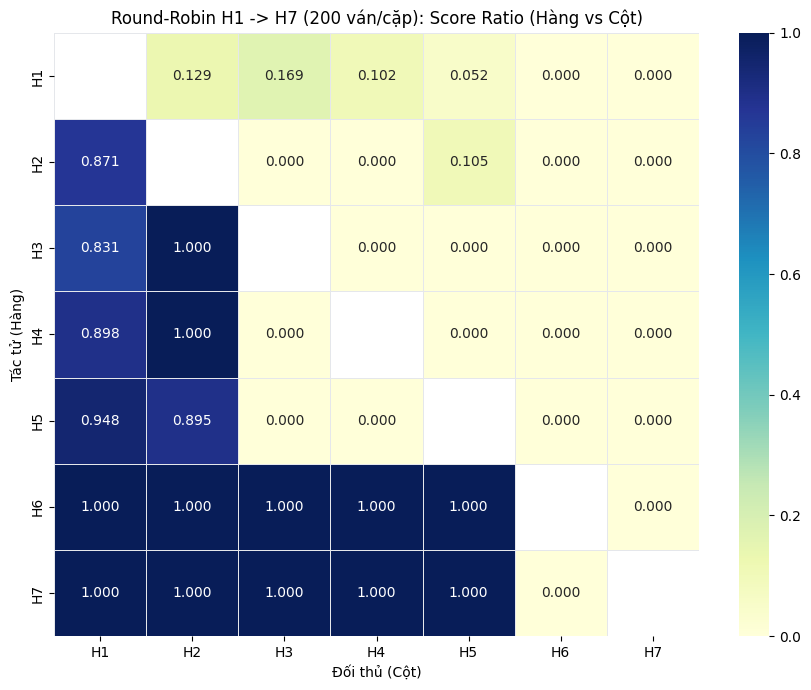

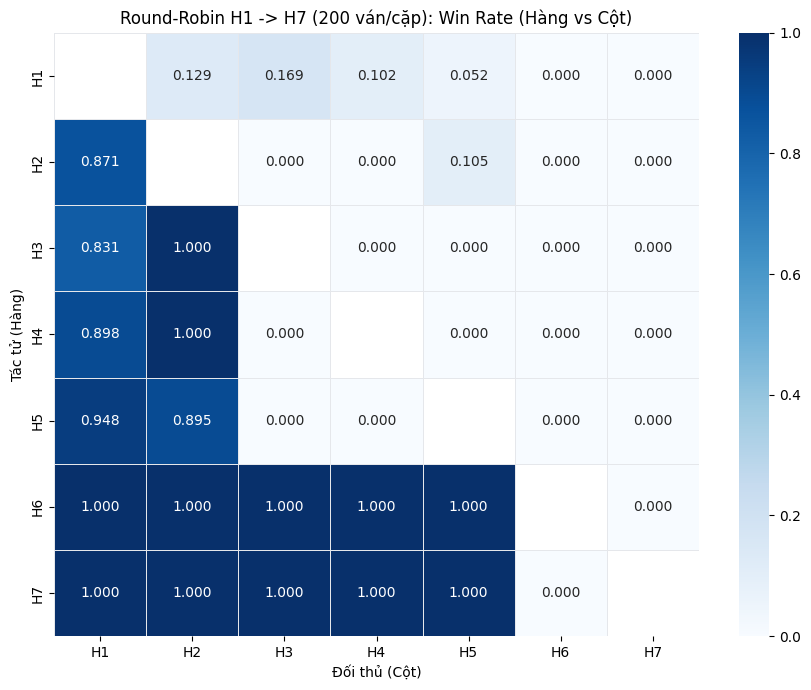

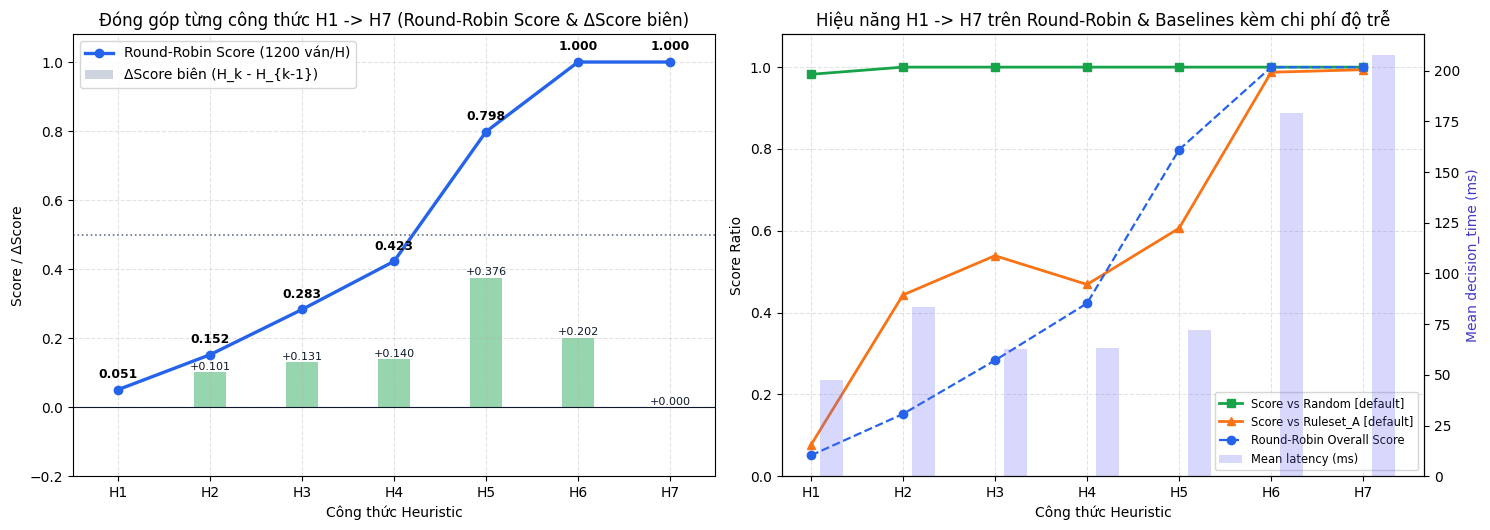

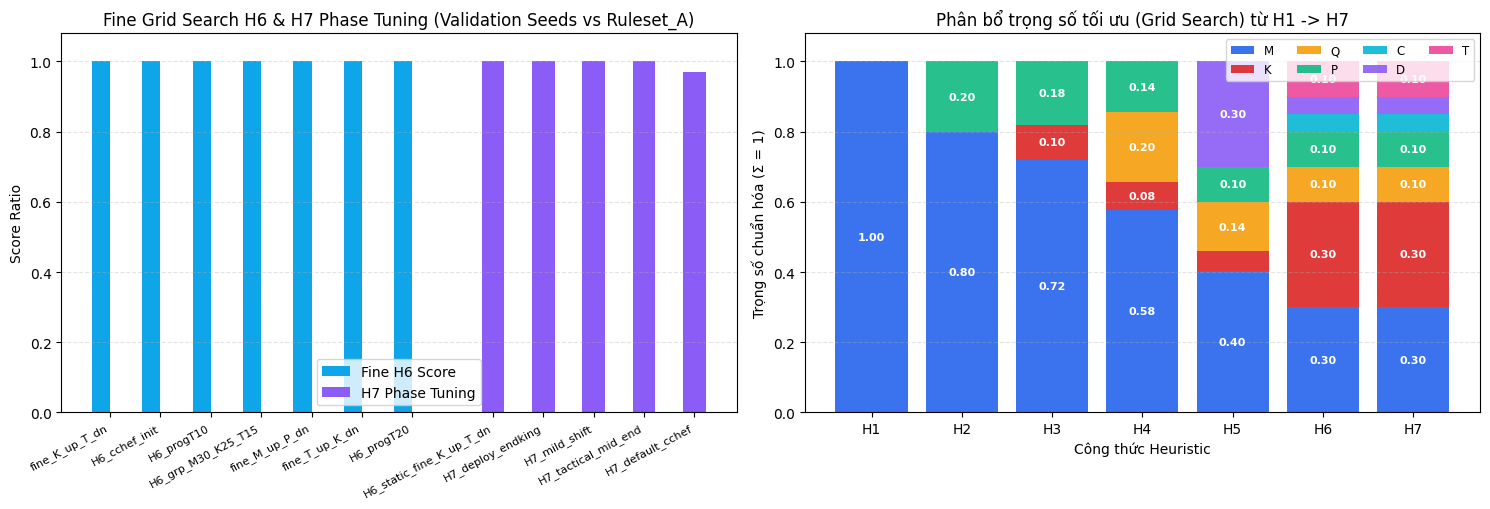

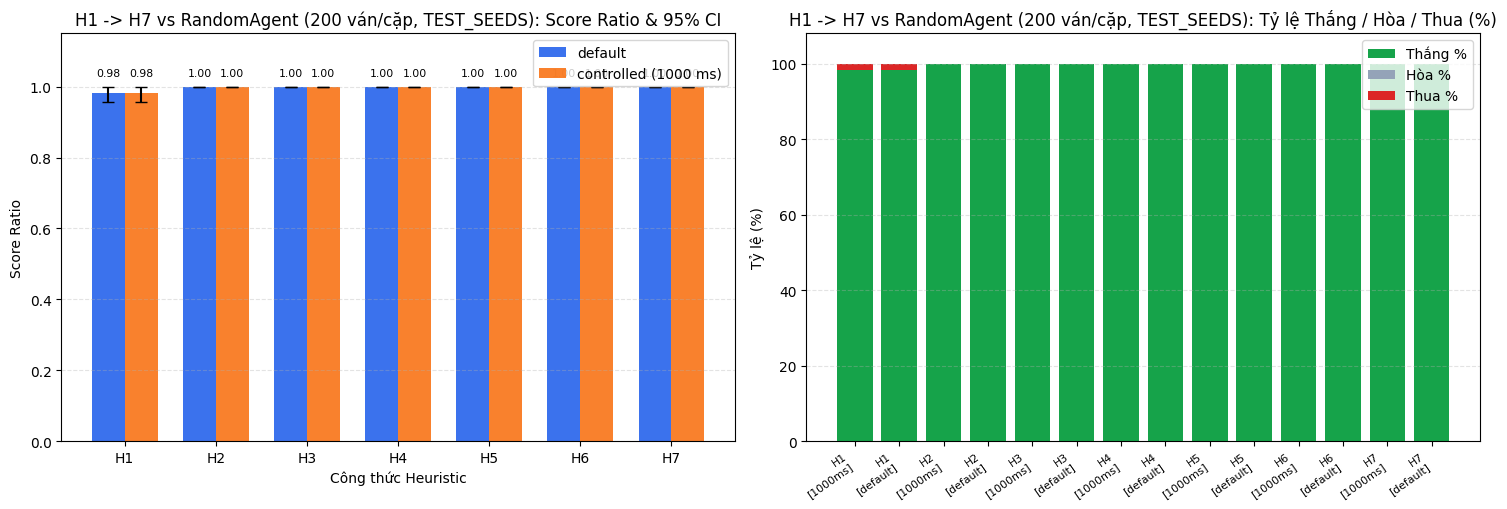

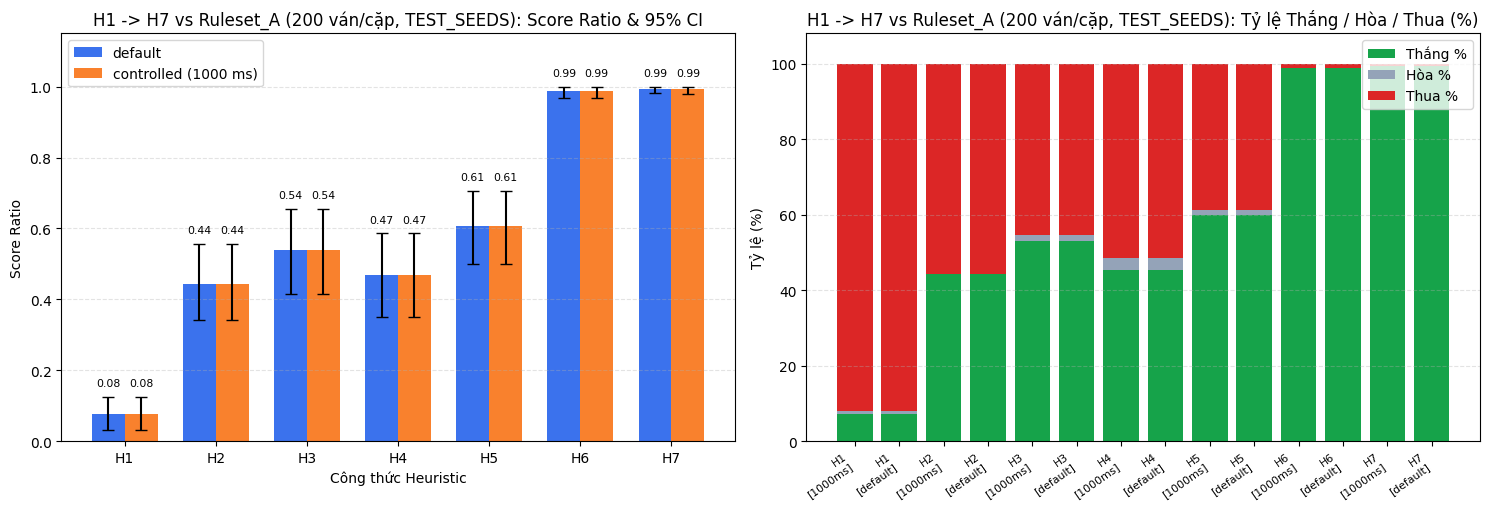

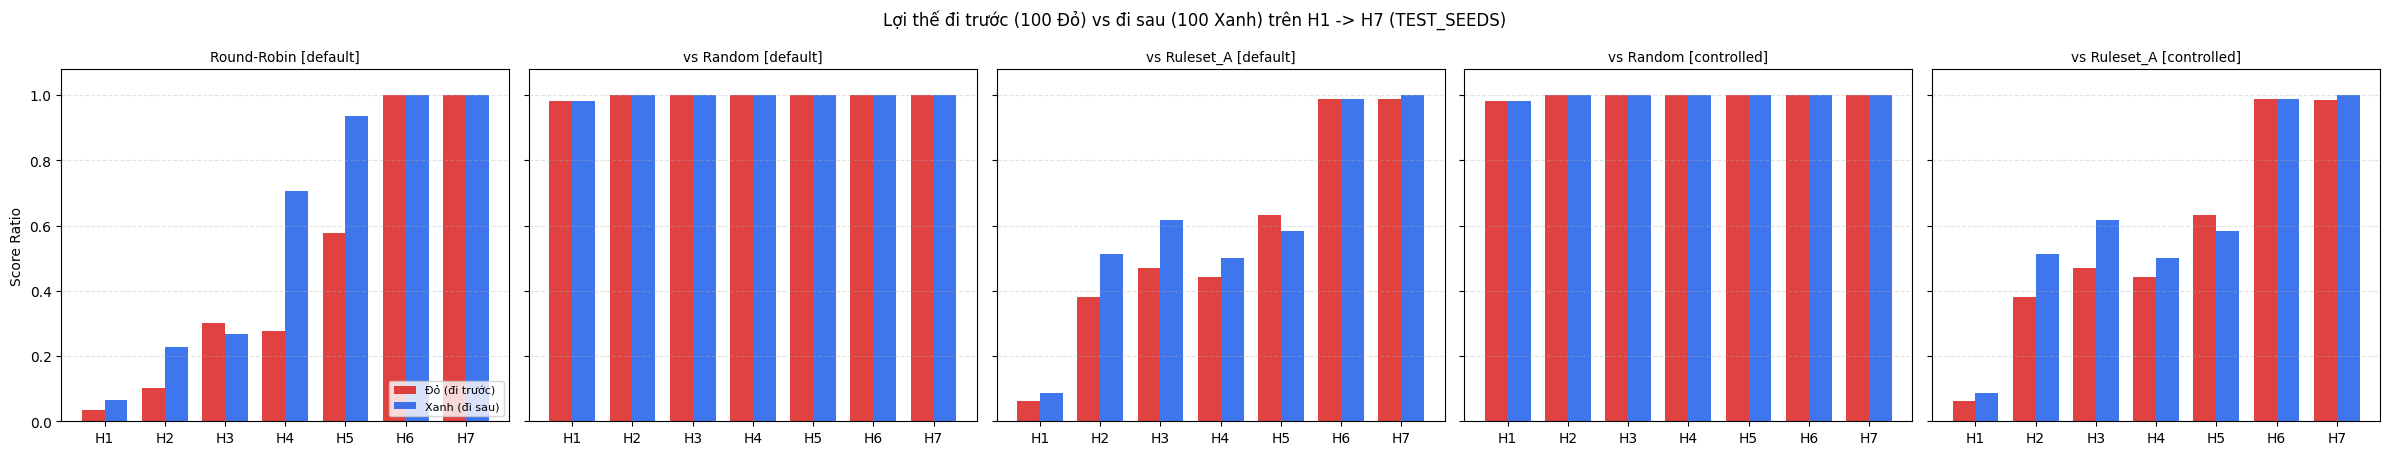

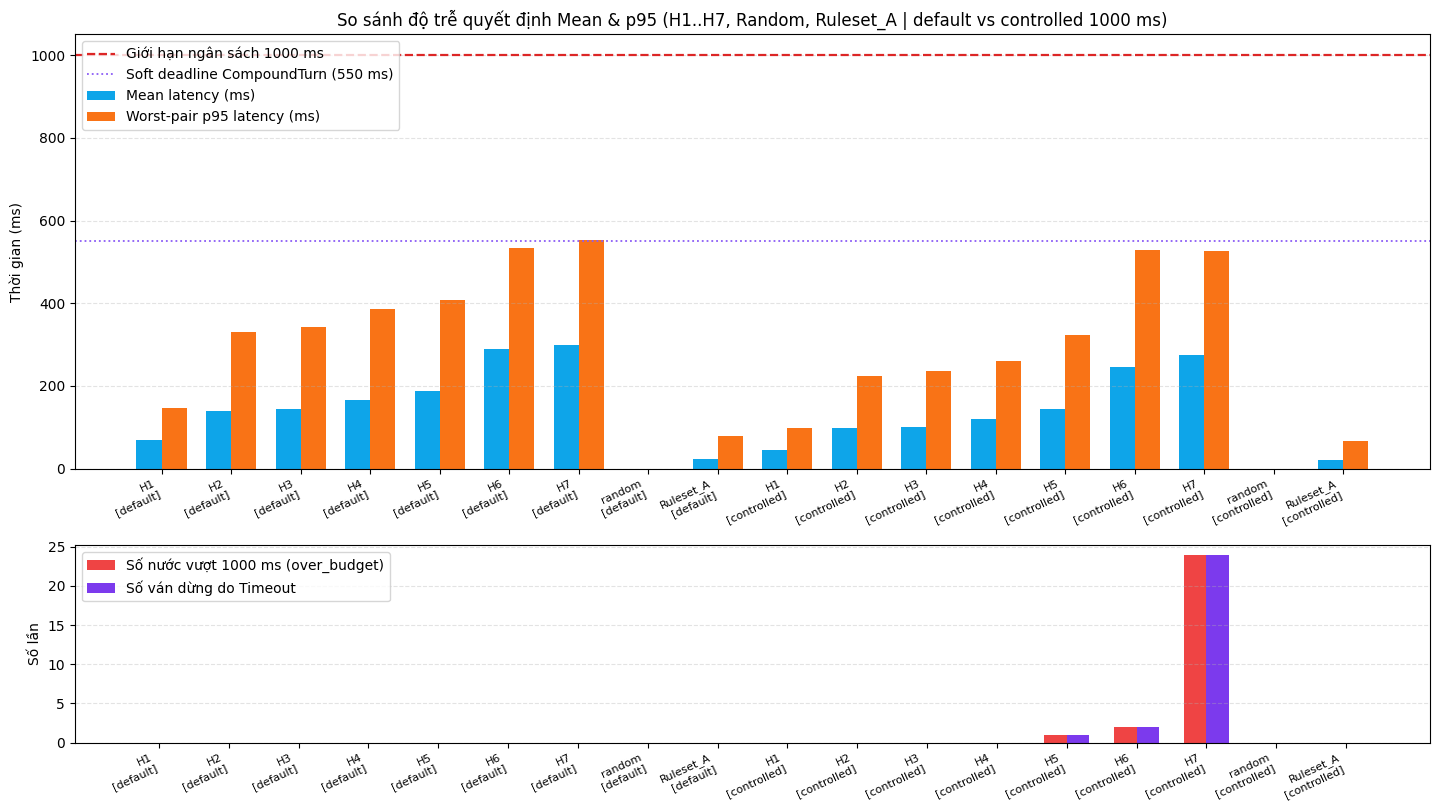

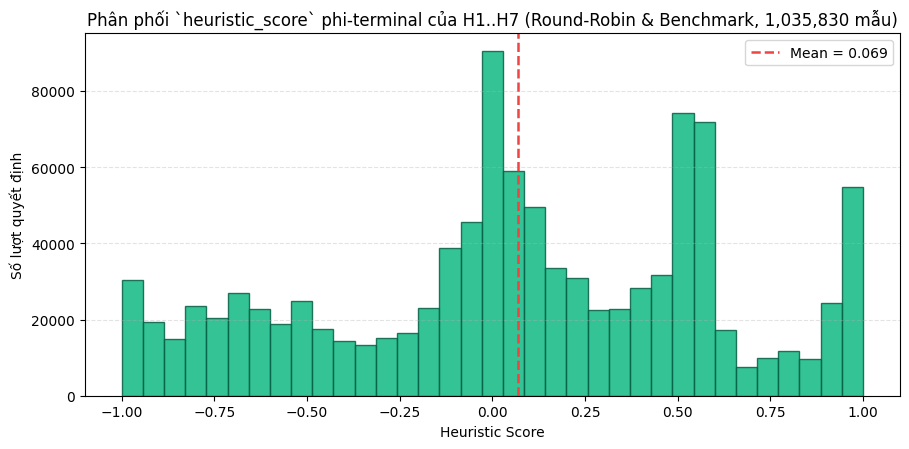

Toàn bộ CSV, JSON, game_records (phân thư mục theo cặp đấu) & PNG (dpi=200) đã lưu tại: D:\Commander-Chess-AI\research\results\09_test_heuristic_agent\cchef_20261112T080947Z


In [10]:
# ===========================================================================
# VII. Trực quan hóa kết quả (fig_01 -> fig_09)
# ===========================================================================
figures_dir = final_logger.run_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Ma trận Round-Robin H1..H7 (Score Ratio & Win Rate)
plot_matchup_heatmap(
    rr_score_matrix,
    title=f"Round-Robin H1 -> H7 ({ROUND_ROBIN_GAMES} ván/cặp): Score Ratio (Hàng vs Cột)",
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0.0,
    vmax=1.0,
    save_path=figures_dir / "fig_01_round_robin_heatmap_score.png",
    figsize=(8.8, 7.0),
)
plt.show()

plot_matchup_heatmap(
    rr_winrate_matrix,
    title=f"Round-Robin H1 -> H7 ({ROUND_ROBIN_GAMES} ván/cặp): Win Rate (Hàng vs Cột)",
    fmt=".3f",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    save_path=figures_dir / "fig_02_round_robin_heatmap_winrate.png",
    figsize=(8.8, 7.0),
)
plt.show()

# 2. Đóng góp của từng công thức H1 -> H7 (Round-Robin Score, Delta Score, & Baseline Scores + Latency)
fig_fc, (ax_fc1, ax_fc2) = plt.subplots(1, 2, figsize=(15.0, 5.4))
x_v = np.arange(len(rr_overall_df))
y_rr = rr_overall_df["score_ratio"].fillna(0.0).astype(float).to_numpy()
d_rr = rr_overall_df["delta_score_vs_prev"].fillna(0.0).astype(float).to_numpy()

ax_fc1.plot(x_v, y_rr, marker="o", linewidth=2.4, color="#2563eb", label=f"Round-Robin Score ({max(1, len(VARIANT_NAMES)-1)*ROUND_ROBIN_GAMES} ván/H)")
bar_colors = ["#94a3b8" if k == 0 else ("#16a34a" if d >= 0 else "#dc2626") for k, d in enumerate(d_rr)]
ax_fc1.bar(x_v, d_rr, width=0.35, alpha=0.45, color=bar_colors, label="ΔScore biên (H_k - H_{k-1})")
ax_fc1.axhline(0.5, color="#64748b", linestyle=":", linewidth=1.2)
ax_fc1.axhline(0.0, color="#0f172a", linewidth=0.8)
for xi, yi, di in zip(x_v, y_rr, d_rr):
    ax_fc1.text(xi, yi + 0.025, f"{yi:.3f}", ha="center", va="bottom", fontsize=8.8, fontweight="bold")
    if xi > 0:
        ax_fc1.text(xi, di + (0.015 if di >= 0 else -0.025), f"{di:+.3f}", ha="center", va="center", fontsize=8.0, color="#0f172a")
ax_fc1.set_xticks(x_v)
ax_fc1.set_xticklabels(rr_overall_df["variant"].tolist())
ax_fc1.set_ylim(-0.20, 1.08)
ax_fc1.set_title("Đóng góp từng công thức H1 -> H7 (Round-Robin Score & ΔScore biên)")
ax_fc1.set_xlabel("Công thức Heuristic")
ax_fc1.set_ylabel("Score / ΔScore")
ax_fc1.legend(loc="upper left")
ax_fc1.grid(True, linestyle="--", alpha=0.35)

if "rand_default_score" in contrib_df.columns:
    ax_fc2.plot(x_v, contrib_df["rand_default_score"].fillna(0.0).astype(float), marker="s", linewidth=2.0, color="#16a34a", label="Score vs Random [default]")
if "rulesA_default_score" in contrib_df.columns:
    ax_fc2.plot(x_v, contrib_df["rulesA_default_score"].fillna(0.0).astype(float), marker="^", linewidth=2.0, color="#f97316", label=f"Score vs {RULES_LABEL} [default]")
ax_fc2.plot(x_v, y_rr, marker="o", linestyle="--", linewidth=1.6, color="#2563eb", label="Round-Robin Overall Score")
ax_fc2.set_xticks(x_v)
ax_fc2.set_xticklabels(contrib_df["variant"].tolist())
ax_fc2.set_ylim(0.0, 1.08)
ax_fc2.set_title("Hiệu năng H1 -> H7 trên Round-Robin & Baselines kèm chi phí độ trễ")
ax_fc2.set_xlabel("Công thức Heuristic")
ax_fc2.set_ylabel("Score Ratio")
ax_fc2.grid(True, linestyle="--", alpha=0.35)

ax_fc2_lat = ax_fc2.twinx()
ax_fc2_lat.bar(x_v + 0.22, rr_overall_df["mean_decision_ms"].fillna(0.0).astype(float), width=0.25, alpha=0.25, color="#6366f1", label="Mean latency (ms)")
ax_fc2_lat.set_ylabel("Mean decision_time (ms)", color="#4338ca")

h1, l1 = ax_fc2.get_legend_handles_labels()
h2, l2 = ax_fc2_lat.get_legend_handles_labels()
ax_fc2.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=8.3)

fig_fc.tight_layout()
fig_fc.savefig(figures_dir / "fig_03_formula_contribution_h1_h7.png", dpi=200, bbox_inches="tight")
plt.show()

# 3. Grid Search: Tối ưu trọng số H1..H7 & Fine / H7 Phase Tuning
fig_gs, (ax_g1, ax_g2) = plt.subplots(1, 2, figsize=(15.0, 5.2))
fine_plot = grid_fine_df.head(8)
xg1 = np.arange(len(fine_plot))
ax_g1.bar(xg1 - 0.18, fine_plot["score"].fillna(0.0).astype(float), width=0.36, color="#0ea5e9", label="Fine H6 Score")
xg2_off = len(fine_plot)
h7_plot = h7_phase_df
xg2 = np.arange(len(h7_plot)) + xg2_off + 0.6
ax_g1.bar(xg2, h7_plot["score"].fillna(0.0).astype(float), width=0.45, color="#8b5cf6", label="H7 Phase Tuning")
all_xticks = list(xg1) + list(xg2)
all_xlabels = fine_plot["weight_config_id"].tolist() + h7_plot["preset_id"].tolist()
ax_g1.set_xticks(all_xticks)
ax_g1.set_xticklabels(all_xlabels, rotation=28, ha="right", fontsize=8.0)
ax_g1.set_ylim(0.0, 1.08)
ax_g1.set_title(f"Fine Grid Search H6 & H7 Phase Tuning (Validation Seeds vs {RULES_LABEL})")
ax_g1.set_ylabel("Score Ratio")
ax_g1.legend()
ax_g1.grid(axis="y", linestyle="--", alpha=0.35)

wt_colors = {
    "M": "#2563eb", "K": "#dc2626", "Q": "#f59e0b",
    "P": "#10b981", "C": "#06b6d4", "D": "#8b5cf6", "T": "#ec4899",
}
xw = np.arange(len(tuned_weights_df))
bottom_w = np.zeros(len(tuned_weights_df))
for feat in FEATURE_NAMES:
    vals_w = tuned_weights_df[feat].fillna(0.0).astype(float).to_numpy()
    ax_g2.bar(xw, vals_w, bottom=bottom_w, color=wt_colors[feat], label=feat, alpha=0.9)
    for idx_w, (bw, vw) in enumerate(zip(bottom_w, vals_w)):
        if vw >= 0.08:
            ax_g2.text(idx_w, bw + vw / 2.0, f"{vw:.2f}", ha="center", va="center", color="white", fontsize=8.0, fontweight="bold")
    bottom_w += vals_w
ax_g2.set_xticks(xw)
ax_g2.set_xticklabels(tuned_weights_df["variant"].tolist())
ax_g2.set_ylim(0.0, 1.08)
ax_g2.set_title("Phân bổ trọng số tối ưu (Grid Search) từ H1 -> H7")
ax_g2.set_xlabel("Công thức Heuristic")
ax_g2.set_ylabel("Trọng số chuẩn hóa (Σ = 1)")
ax_g2.legend(loc="upper right", ncol=4, fontsize=8.5)
ax_g2.grid(axis="y", linestyle="--", alpha=0.35)

fig_gs.tight_layout()
fig_gs.savefig(figures_dir / "fig_04_grid_search_weights.png", dpi=200, bbox_inches="tight")
plt.show()


# 4 & 5. Helper vẽ đối đầu Random & Ruleset_A ở 2 chế độ default vs controlled (1000 ms)
def _plot_vs_baseline_dual_budget(opp_label: str, fig_title: str, save_file: Path) -> None:
    sub = bench_df[bench_df["agent_b"] == opp_label].copy()
    sub["variant_order"] = sub["agent_a"].apply(lambda v: VARIANT_NAMES.index(v) if v in VARIANT_NAMES else 99)
    sub = sub.sort_values(["variant_order", "budget_mode"])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.0, 5.2))
    variants_list = list(VARIANT_NAMES)
    x = np.arange(len(variants_list))
    modes_present = [m for m in ("default", "controlled") if m in sub["budget_mode"].unique()]
    w_bar = 0.36 if len(modes_present) == 2 else 0.55
    mode_colors = {"default": "#2563eb", "controlled": "#f97316"}
    mode_names = {"default": "default", "controlled": "controlled (1000 ms)"}

    for m_idx, bmode in enumerate(modes_present):
        df_m = sub[sub["budget_mode"] == bmode].set_index("agent_a").reindex(variants_list)
        scores = df_m["score_a"].fillna(0.0).astype(float).to_numpy()
        lows = np.clip(scores - df_m["score_ci_low"].fillna(0.0).astype(float).to_numpy(), 0.0, None)
        highs = np.clip(df_m["score_ci_high"].fillna(0.0).astype(float).to_numpy() - scores, 0.0, None)
        offset = (m_idx - (len(modes_present) - 1) / 2.0) * w_bar
        bars = ax1.bar(x + offset, scores, width=w_bar, yerr=np.vstack([lows, highs]), capsize=4, color=mode_colors[bmode], alpha=0.9, label=mode_names[bmode])
        for b_rect, sc_val, hi_val in zip(bars, scores, highs):
            y_txt = min(1.06, sc_val + hi_val + 0.025)
            ax1.text(b_rect.get_x() + b_rect.get_width() / 2.0, y_txt, f"{sc_val:.2f}", ha="center", va="bottom", fontsize=7.8)

    ax1.set_xticks(x)
    ax1.set_xticklabels(variants_list)
    ax1.set_ylim(0.0, 1.15)
    ax1.set_title(f"{fig_title}: Score Ratio & 95% CI")
    ax1.set_xlabel("Công thức Heuristic")
    ax1.set_ylabel("Score Ratio")
    ax1.legend()
    ax1.grid(axis="y", linestyle="--", alpha=0.35)

    df_wdl = sub.copy()
    df_wdl["lbl"] = df_wdl["agent_a"] + "\n[" + df_wdl["budget_mode"].replace({"controlled": "1000ms"}) + "]"
    x2 = np.arange(len(df_wdl))
    w_pct = df_wdl["win_rate_a"].fillna(0.0).astype(float).to_numpy() * 100.0
    d_pct = df_wdl["draw_rate"].fillna(0.0).astype(float).to_numpy() * 100.0
    l_pct = df_wdl["loss_rate_a"].fillna(0.0).astype(float).to_numpy() * 100.0
    ax2.bar(x2, w_pct, color="#16a34a", label="Thắng %")
    ax2.bar(x2, d_pct, bottom=w_pct, color="#94a3b8", label="Hòa %")
    ax2.bar(x2, l_pct, bottom=w_pct + d_pct, color="#dc2626", label="Thua %")
    ax2.set_xticks(x2)
    ax2.set_xticklabels(df_wdl["lbl"].tolist(), rotation=35, ha="right", fontsize=7.8)
    ax2.set_ylim(0.0, 108.0)
    ax2.set_title(f"{fig_title}: Tỷ lệ Thắng / Hòa / Thua (%)")
    ax2.set_ylabel("Tỷ lệ (%)")
    ax2.legend(loc="upper right")
    ax2.grid(axis="y", linestyle="--", alpha=0.35)

    fig.tight_layout()
    fig.savefig(save_file, dpi=200, bbox_inches="tight")
    plt.show()


_plot_vs_baseline_dual_budget(
    "random",
    f"H1 -> H7 vs RandomAgent ({BENCHMARK_GAMES} ván/cặp, TEST_SEEDS)",
    figures_dir / "fig_05_h1_h7_vs_random_budgets.png",
)

_plot_vs_baseline_dual_budget(
    RULES_LABEL,
    f"H1 -> H7 vs {RULES_LABEL} ({BENCHMARK_GAMES} ván/cặp, TEST_SEEDS)",
    figures_dir / "fig_06_h1_h7_vs_rulesA_budgets.png",
)

# 6. So sánh phe Đỏ (đi trước, 100 ván) vs phe Xanh (đi sau, 100 ván) trên H1..H7
rb_contexts = [("RoundRobin_H1_H7", "default", "Round-Robin [default]")]
for bmode in benchmark_modes:
    rb_contexts.append(("random", bmode, f"vs Random [{bmode}]"))
    rb_contexts.append((RULES_LABEL, bmode, f"vs {RULES_LABEL} [{bmode}]"))

n_ctx = len(rb_contexts)
fig_rb, axes_rb = plt.subplots(1, n_ctx, figsize=(4.8 * n_ctx, 4.6), sharey=True)
if n_ctx == 1:
    axes_rb = [axes_rb]
for ax_r, (opp_c, bm_c, title_c) in zip(axes_rb, rb_contexts):
    sub_c = red_blue_df[(red_blue_df["opponent"] == opp_c) & (red_blue_df["budget_mode"] == bm_c)]
    xr = np.arange(len(VARIANT_NAMES))
    red_vals = [float(sub_c[(sub_c["agent"] == v) & (sub_c["side"] == "red")]["score_ratio"].iloc[0]) if not sub_c[(sub_c["agent"] == v) & (sub_c["side"] == "red")].empty else 0.0 for v in VARIANT_NAMES]
    blue_vals = [float(sub_c[(sub_c["agent"] == v) & (sub_c["side"] == "blue")]["score_ratio"].iloc[0]) if not sub_c[(sub_c["agent"] == v) & (sub_c["side"] == "blue")].empty else 0.0 for v in VARIANT_NAMES]
    ax_r.bar(xr - 0.19, red_vals, width=0.38, color="#dc2626", alpha=0.88, label="Đỏ (đi trước)")
    ax_r.bar(xr + 0.19, blue_vals, width=0.38, color="#2563eb", alpha=0.88, label="Xanh (đi sau)")
    ax_r.set_xticks(xr)
    ax_r.set_xticklabels(list(VARIANT_NAMES))
    ax_r.set_ylim(0.0, 1.08)
    ax_r.set_title(title_c, fontsize=9.8)
    ax_r.grid(axis="y", linestyle="--", alpha=0.35)
axes_rb[0].set_ylabel("Score Ratio")
axes_rb[0].legend(loc="lower right", fontsize=8.0)
fig_rb.suptitle("Lợi thế đi trước (100 Đỏ) vs đi sau (100 Xanh) trên H1 -> H7 (TEST_SEEDS)", fontsize=12)
fig_rb.tight_layout()
fig_rb.savefig(figures_dir / "fig_07_red_vs_blue_advantage.png", dpi=200, bbox_inches="tight")
plt.show()

# 7. Độ trễ quyết định Mean/p95 & Budget Exceeded (default vs controlled 1000 ms)
lat_rows: list[dict[str, Any]] = []
for bmode in benchmark_modes:
    sub_m = bench_df[bench_df["budget_mode"] == bmode]
    for var in VARIANT_NAMES:
        v_rows = sub_m[sub_m["agent_a"] == var]
        if not v_rows.empty:
            lat_rows.append({
                "agent": f"{var}\n[{bmode}]",
                "mean_ms": float(v_rows["mean_decision_ms_a"].mean()),
                "p95_ms": float(v_rows["p95_decision_ms_a"].max()),
                "over_budget": int(v_rows["budget_exceeded_a"].sum()),
                "timeouts": int(v_rows["timeout_games"].sum()),
            })
    for opp_l in ("random", RULES_LABEL):
        o_rows = sub_m[sub_m["agent_b"] == opp_l]
        if not o_rows.empty:
            lat_rows.append({
                "agent": f"{opp_l}\n[{bmode}]",
                "mean_ms": float(o_rows["mean_decision_ms_b"].mean()),
                "p95_ms": float(o_rows["p95_decision_ms_b"].max()),
                "over_budget": int(o_rows["budget_exceeded_b"].sum()),
                "timeouts": 0,
            })
lat_all_df = pd.DataFrame(lat_rows)

fig_lt, (ax_l1, ax_l2) = plt.subplots(2, 1, figsize=(14.5, 8.2), gridspec_kw={"height_ratios": [2.2, 1.0]})
xl = np.arange(len(lat_all_df))
ax_l1.bar(xl - 0.18, lat_all_df["mean_ms"], width=0.36, color="#0ea5e9", label="Mean latency (ms)")
ax_l1.bar(xl + 0.18, lat_all_df["p95_ms"], width=0.36, color="#f97316", label="Worst-pair p95 latency (ms)")
ax_l1.axhline(1000.0, color="#dc2626", linestyle="--", linewidth=1.6, label="Giới hạn ngân sách 1000 ms")
ax_l1.axhline(550.0, color="#8b5cf6", linestyle=":", linewidth=1.3, label="Soft deadline CompoundTurn (550 ms)")
ax_l1.set_xticks(xl)
ax_l1.set_xticklabels(lat_all_df["agent"].tolist(), rotation=25, ha="right", fontsize=8.0)
ax_l1.set_ylabel("Thời gian (ms)")
ax_l1.set_title("So sánh độ trễ quyết định Mean & p95 (H1..H7, Random, Ruleset_A | default vs controlled 1000 ms)")
ax_l1.legend(loc="upper left")
ax_l1.grid(axis="y", linestyle="--", alpha=0.35)

ax_l2.bar(xl - 0.16, lat_all_df["over_budget"], width=0.32, color="#ef4444", label="Số nước vượt 1000 ms (over_budget)")
ax_l2.bar(xl + 0.16, lat_all_df["timeouts"], width=0.32, color="#7c3aed", label="Số ván dừng do Timeout")
ax_l2.set_xticks(xl)
ax_l2.set_xticklabels(lat_all_df["agent"].tolist(), rotation=25, ha="right", fontsize=8.0)
ax_l2.set_ylabel("Số lần")
ax_l2.legend(loc="upper left")
ax_l2.grid(axis="y", linestyle="--", alpha=0.35)

fig_lt.tight_layout()
fig_lt.savefig(figures_dir / "fig_08_latency_and_timeout_1000ms.png", dpi=200, bbox_inches="tight")
plt.show()

# 8. Phân phối `heuristic_score` chuẩn hóa của CCHEF (đọc theo chunk từ moves.csv)
if all_non_term_scores.size > 0:
    fig_hd, ax_hd = plt.subplots(figsize=(9.2, 4.6))
    ax_hd.hist(all_non_term_scores, bins=35, color="#10b981", alpha=0.85, edgecolor="#065f46")
    mean_sc = float(np.mean(all_non_term_scores))
    ax_hd.axvline(mean_sc, color="#ef4444", linestyle="--", linewidth=1.8, label=f"Mean = {mean_sc:.3f}")
    ax_hd.set_title(f"Phân phối `heuristic_score` phi-terminal của H1..H7 (Round-Robin & Benchmark, {all_non_term_scores.size:,} mẫu)")
    ax_hd.set_xlabel("Heuristic Score")
    ax_hd.set_ylabel("Số lượt quyết định")
    ax_hd.legend()
    ax_hd.grid(axis="y", linestyle="--", alpha=0.35)
    fig_hd.tight_layout()
    fig_hd.savefig(figures_dir / "fig_09_cchef_score_dist.png", dpi=200, bbox_inches="tight")
    plt.show()

print("Toàn bộ CSV, JSON, game_records (phân thư mục theo cặp đấu) & PNG (dpi=200) đã lưu tại:", final_logger.run_dir)

## VIII. Nhận xét và kết luận

*(Chỉ điền nhận xét định lượng sau khi chạy xong thực nghiệm và đối chiếu với W&B dashboard + CSV đầu ra; không điền số ước đoán)*

1. **Tính đúng đắn CCHEF (`HE-01` → `HE-16`) & cân bằng Game Engine:**
   - Toàn bộ `HE-01..HE-16` có đạt 100% không? Kiểm chứng Sở chỉ huy `10đ`, Tư lệnh `0đ`, tổ hợp 3 tầng `70đ`, đòn `BOMBARD` tại chỗ của Hải quân, vùng phòng không `AA`, đối xứng Bắc–Nam `E(s, Đỏ) = -E(s, Xanh)` trên cả 7 biến thể `H1..H7`.
2. **Kết quả tối ưu trọng số bằng Grid Search (`grid_search_*.csv`, `grid_search_optimized_weights.csv`):**
   - Bộ trọng số tối ưu mà Coarse-to-Fine Grid Search tìm ra cho từng cấp độ `H1 → H7` là gì? Các thành phần `M, K, Q, P, C, D, T` nhận tỷ trọng bao nhiêu ở phiên bản tốt nhất và pha động `H7` (`h7_phase_tuning.csv`) có vượt `H6` tĩnh trên `VALIDATION_SEEDS` hay không?
3. **Đóng góp của từng công thức trong Round-Robin `H1 → H7` (`21×200 = 4,200` ván, `round_robin_overall.csv`, `formula_contribution_h1_h7.csv`):**
   - Theo ma trận 7×7 (`fig_01`, `fig_02`) và biểu đồ đóng góp biên (`fig_03`), bước nhảy Score $\Delta\text{Score}(H_k - H_{k-1})$ nào lớn nhất (`+P/C`, `+K`, `+Q`, `+D`, `+T/CO`, hay pha động `H7`)? Có hiện tượng công thức cấp cao hơn bị giảm điểm hay chậm hơn đáng kể so với cấp trước không?
4. **Chất lượng thi đấu trước Baseline & tác động của giới hạn `1000 ms` (`pair_results.csv`, `fig_05`–`fig_08`):**
   - So sánh Score + 95% CI và W/D/L của từng `H1 → H7` trước `RandomAgent` và `RuleBasedAgent` (`Ruleset_A`, `enable_check_rule = False`) ở cả hai chế độ `default` (`2,800` ván) và `controlled 1000 ms` (`2,800` ván).
   - Ở chế độ `controlled (1000 ms)`, biến thể nào (`H6`, `H7` với `CompoundTurn`) có nước vượt `1000 ms` (`budget_exceeded` / `timeout_games`) và hiệu năng thực tế thay đổi ra sao so với `default`?
   - Lợi thế đi trước (`100 Đỏ` vs `100 Xanh` trong `red_blue_splits.csv` & `fig_07`) nghiêng về bên nào qua `H1 → H7`?
5. **Phân tích sai lầm chiến thuật & giới hạn phạm vi:**
   - Soi từ `blunder_high_score_losses.json` (những ván có điểm CCHEF > `0.15` nhưng thua ở các bước sau — hạn chế của đánh giá nông 1 ply, là động lực trực tiếp cho Minimax & Alpha-Beta ở notebook `10` và `11`).
   - Mọi kết luận chỉ áp dụng trong thiết lập **Cơ bản – Tổng lực**, `MAX_TURNS = 200`, `draw_on_max_turns = False`, không dùng Search Tree (`nodes_visited = NA`, `simulations = NA`).